# Klasifikasi Citra Pakaian Fashion-MNIST dengan DNN dan CNN

Proyek Deep Learning kelompok. Notebook ini berisi alur lengkap: pencatatan lingkungan, eksplorasi data, pembersihan data, preprocessing, input pipeline `tf.data`, tiga arsitektur (MLP baseline, CNN buatan sendiri, transfer learning MobileNetV2), studi ablasi dan eksperimen hyperparameter, evaluasi, analisis error, dua fitur unik (**Grad-CAM** dan **kompresi TFLite**), dan penyimpanan model untuk deployment.

**Cara menjalankan (Google Colab):** Runtime > Change runtime type > pilih GPU (T4), lalu Runtime > Run all. Jalankan **satu kali sampai selesai**, lalu ambil seluruh angka laporan, README, dan video dari keluaran run itu (lihat sel terakhir, `ringkasan_angka_laporan.json`). Menjalankan ulang dapat mengubah angka sedikit karena GPU tidak sepenuhnya deterministik.

**Pengaturan waktu:** eksperimen inti diulang dengan beberapa seed (`SEEDS` di sel pertama). Bila waktu terbatas, ubah `SEEDS = [42]`.

**Dataset:** Fashion-MNIST (Zalando Research), 70.000 citra grayscale 28x28 dalam 10 kelas. Data dimuat lewat `keras.datasets`, yang berisi data identik dengan dataset Kaggle `zalando-research/fashionmnist` (60.000 latih, 10.000 uji).

**Keluaran:** folder `figures/` (gambar untuk laporan) dan `outputs/` (tabel hasil, `outputs/models/` berisi tiga file untuk deployment, `environment.json`, `requirements_pinned.txt`).

## 1. Setup, reproducibility, dan pencatatan lingkungan

In [1]:
import os, sys, time, json, random, platform, subprocess, hashlib, shutil
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from IPython.display import display

SEED = 42                 # seed utama: pembagian data, pengacakan pipeline, bootstrap
SEEDS = [42, 43, 44]      # seed untuk pengulangan eksperimen inti (ubah ke [42] bila waktu terbatas)
keras.utils.set_random_seed(SEED)   # mengunci seed Python, NumPy, dan TensorFlow

os.makedirs("figures", exist_ok=True)          # gambar untuk laporan
os.makedirs("outputs/models", exist_ok=True)   # tabel hasil dan tiga file model untuk deployment

In [2]:
# Pencatatan teknologi dan lingkungan (untuk bagian "Teknologi yang digunakan" di laporan)
ENV = {
    "python": sys.version.split()[0],
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "pillow": PIL.__version__,
    "sistem_operasi": platform.platform(),
}
gpus = tf.config.list_physical_devices("GPU")
ENV["gpu_terdeteksi"] = len(gpus) > 0
try:
    ENV["gpu"] = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True).strip()
except Exception:
    ENV["gpu"] = "tidak tersedia (berjalan di CPU)"

with open("outputs/environment.json", "w") as f:
    json.dump(ENV, f, indent=2)
for k, v in ENV.items():
    print(f"{k:16s}: {v}")

python          : 3.13.16
tensorflow      : 2.21.0
keras           : 3.13.2
numpy           : 2.4.6
pandas          : 2.2.3
scikit-learn    : 1.6.1
matplotlib      : 3.10.0
seaborn         : 0.13.2
pillow          : 11.3.0
sistem_operasi  : Linux-6.6.159+-x86_64-with-glibc2.39
gpu_terdeteksi  : True
gpu             : Tesla T4, 15360 MiB


## 2. Memuat data dan eksplorasi (EDA)

Bagian ini mendukung kriteria **kompleksitas masalah dan dataset**. Meski ukurannya kecil, dataset ini memiliki kelas yang sangat mirip secara visual (T-shirt, Shirt, Pullover, Coat) sehingga tidak sesepele MNIST digit. Klaim tentang kelas yang sulit dibedakan nanti dibuktikan lewat confusion matrix, bukan hanya diasumsikan.

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Data latih penuh :", X_train_full.shape, X_train_full.dtype)
print("Data uji         :", X_test.shape)
print("Rentang piksel   :", X_train_full.min(), "-", X_train_full.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data latih penuh : (60000, 28, 28) uint8
Data uji         : (10000, 28, 28)
Rentang piksel   : 0 - 255


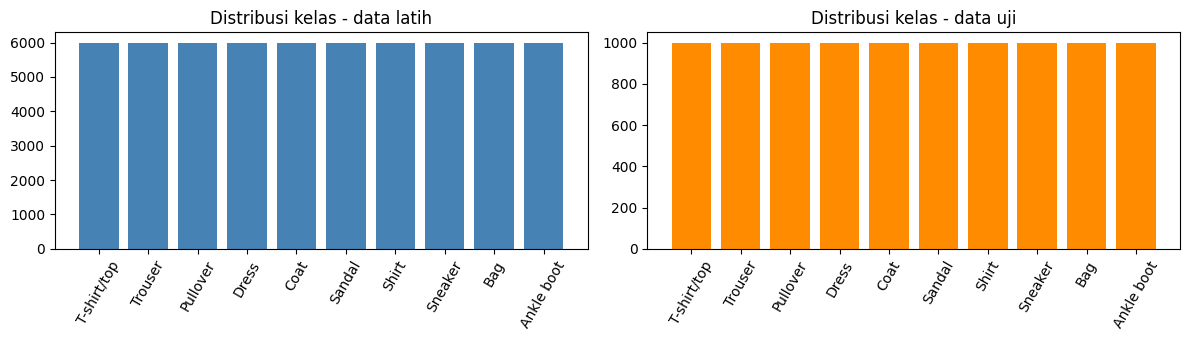

Kelas seimbang (jumlah per kelas sama di data latih): True


In [4]:
# Distribusi kelas
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()
ax[0].bar(CLASS_NAMES, train_counts.values, color="steelblue"); ax[0].set_title("Distribusi kelas - data latih")
ax[1].bar(CLASS_NAMES, test_counts.values, color="darkorange"); ax[1].set_title("Distribusi kelas - data uji")
for a in ax: a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("figures/01_distribusi_kelas.png", dpi=150); plt.show()
print("Kelas seimbang (jumlah per kelas sama di data latih):", train_counts.nunique() == 1)

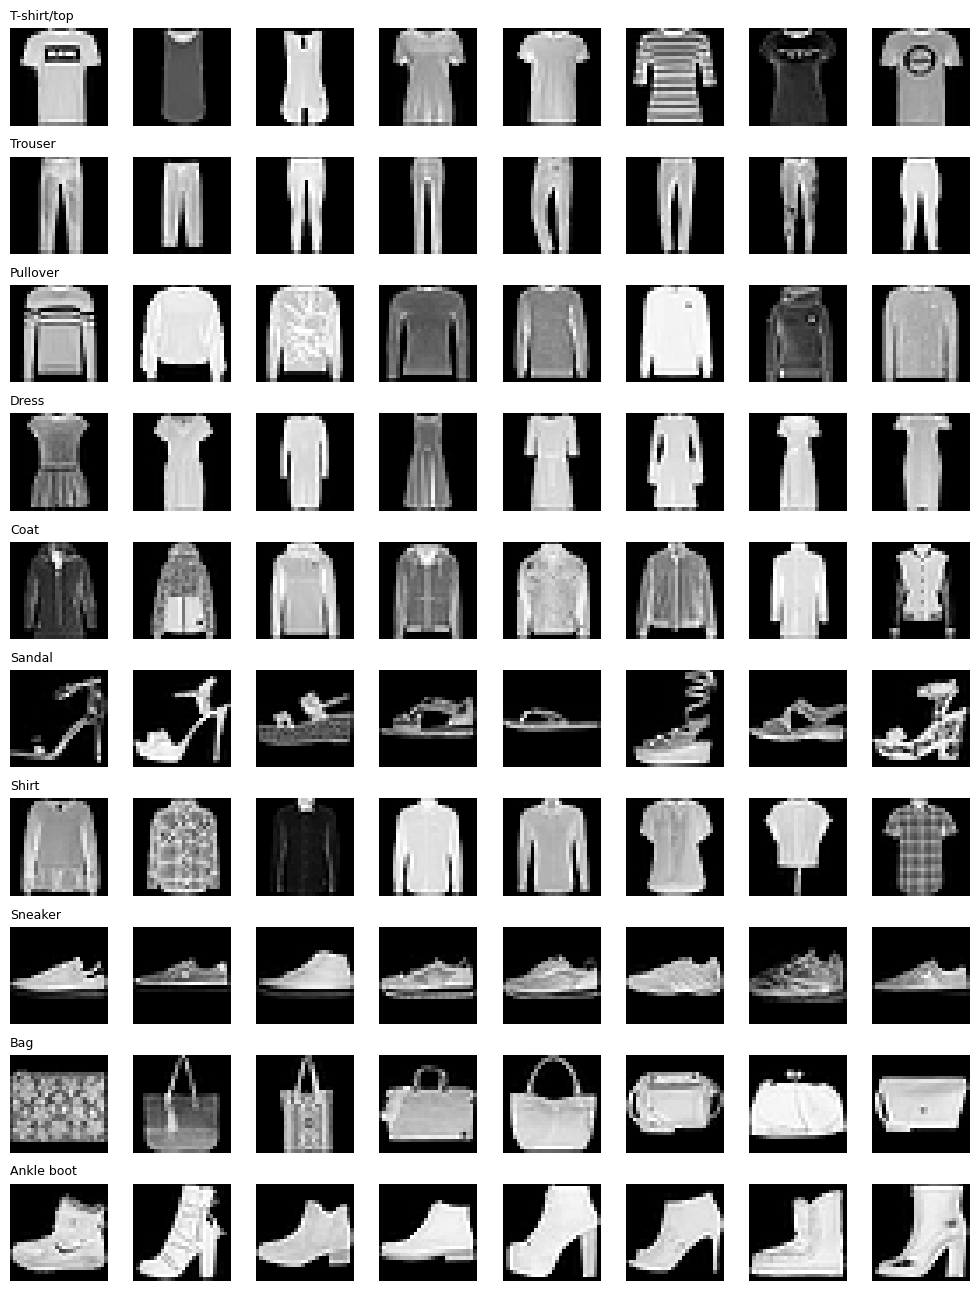

In [5]:
# Contoh citra tiap kelas
fig, axes = plt.subplots(10, 8, figsize=(10, 13))
for c in range(10):
    idx = np.where(y_train_full == c)[0][:8]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train_full[i], cmap="gray"); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig("figures/02_contoh_citra.png", dpi=120); plt.show()

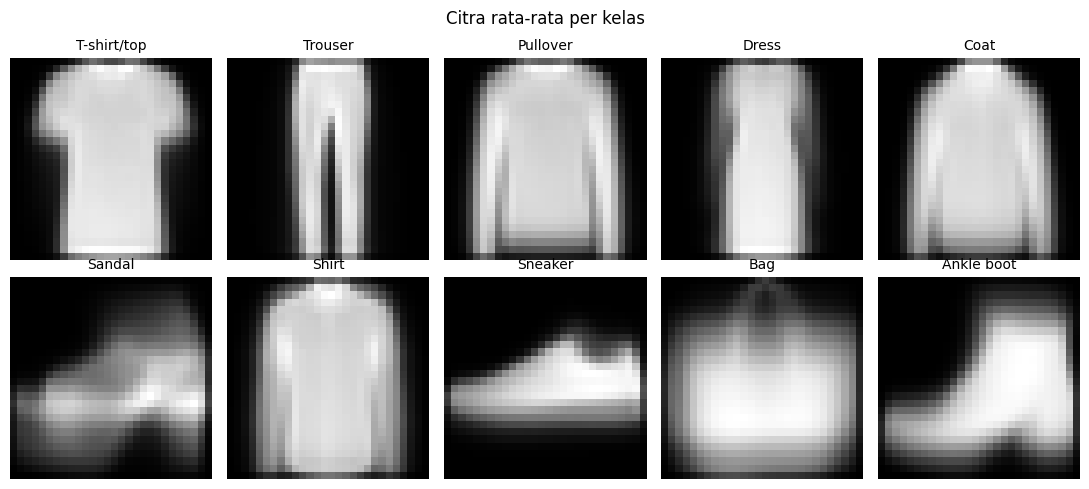

In [6]:
# Citra rata-rata tiap kelas: memperlihatkan kemiripan antar kelas atasan
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[y_train_full == c].mean(axis=0), cmap="gray")
    ax.set_title(CLASS_NAMES[c], fontsize=10); ax.axis("off")
plt.suptitle("Citra rata-rata per kelas")
plt.tight_layout(); plt.savefig("figures/03_citra_rata_rata.png", dpi=150); plt.show()

## 3. Preprocessing data

Langkah yang dilakukan dan alasannya (untuk bagian preprocessing di laporan):

1. **Pembersihan data**: cek citra rusak/kosong, label di luar rentang, duplikat persis, duplikat berlabel konflik (indikasi label salah), dan **tumpang tindih data latih dengan data uji** (sumber kebocoran data). Karena ada pembersihan, jumlah data latih akhir tidak lagi tepat 60.000; tulis angka "60.000 menjadi N" di laporan (tersimpan di `ukuran_data.json`).
2. **Pembagian data** latih/validasi/uji dengan stratifikasi, dilakukan **sebelum** augmentasi atau statistik apa pun dihitung. Validasi dipakai untuk early stopping dan pemilihan model, data uji hanya untuk pelaporan akhir.
3. **Reshape** ke `(N, 28, 28, 1)` karena CNN membutuhkan dimensi channel.
4. **Normalisasi piksel** 0-255 menjadi 0-1 lewat layer `Rescaling` di dalam model. Konstanta 1/255 bersifat tetap (tidak dihitung dari data), sehingga tidak ada risiko kebocoran statistik data uji, dan preprocessing saat training dan inferensi dijamin identik.
5. **Data augmentation** (flip horizontal, rotasi kecil, zoom, translasi) sebagai layer di dalam model, aktif hanya saat training. Flip horizontal dipilih karena pakaian relatif simetris kiri-kanan; flip vertikal tidak dipakai karena mengubah semantik. Manfaat augmentasi **diuji**, bukan diasumsikan, lewat studi ablasi (bagian 7).
6. **Ketidakseimbangan kelas**: dicek pada EDA; bila kelas seimbang, tidak perlu resampling atau class weight. Tidak ada missing value karena data berupa citra utuh.
7. **Input pipeline `tf.data`** (bagian 3.5) dipakai oleh semua model sehingga perbandingan antarmodel adil.

In [7]:
# 3.1 Pembersihan data
def md5s(arr):
    return [hashlib.md5(a.tobytes()).hexdigest() for a in arr]

n0 = len(X_train_full)
h_train, h_test = md5s(X_train_full), md5s(X_test)
test_set = set(h_test)

# a) citra rusak / kosong dan label tidak valid
flat = X_train_full.reshape(n0, -1)
blank_mask = flat.max(axis=1) == 0
bad_label_mask = ~np.isin(y_train_full, np.arange(10))
shape_ok = X_train_full.shape[1:] == (28, 28)

# b) duplikat persis dan duplikat berlabel konflik di data latih
groups = defaultdict(list)
for i, h in enumerate(h_train):
    groups[h].append(i)
dup_groups = [idx for idx in groups.values() if len(idx) > 1]
conflict_groups = [idx for idx in dup_groups if len(set(y_train_full[idx])) > 1]
pure_groups = [idx for idx in dup_groups if len(set(y_train_full[idx])) == 1]

# c) tumpang tindih data latih dengan data uji (kebocoran data)
leak_idx = [i for i, h in enumerate(h_train) if h in test_set]

summary = pd.DataFrame({
    "pemeriksaan": ["Ukuran citra bukan 28x28", "Citra kosong (semua piksel 0)", "Label di luar 0-9",
                    "Kelompok duplikat persis (label sama)", "Kelompok duplikat berlabel konflik",
                    "Citra latih yang juga ada di data uji", "Duplikat di dalam data uji (hanya dilaporkan)"],
    "jumlah": [0 if shape_ok else n0, int(blank_mask.sum()), int(bad_label_mask.sum()),
               len(pure_groups), len(conflict_groups), len(leak_idx), len(h_test) - len(test_set)],
})
display(summary)
summary.to_csv("outputs/ringkasan_pembersihan_data.csv", index=False)

drop = set(np.where(blank_mask | bad_label_mask)[0].tolist()) | set(leak_idx)
for idx in pure_groups:
    drop.update(idx[1:])        # simpan satu, buang salinannya
for idx in conflict_groups:
    drop.update(idx)            # label konflik: buang semua anggotanya
keep = np.array(sorted(set(range(n0)) - drop))
X_train_full, y_train_full = X_train_full[keep], y_train_full[keep]

print(f"\nData latih: {n0} -> {len(X_train_full)} (dibuang {len(drop)})")
assert not (set(md5s(X_train_full)) & test_set), "Masih ada tumpang tindih latih-uji!"
print("Verifikasi: tidak ada citra data latih yang sama dengan data uji.")
print("Jumlah per kelas setelah pembersihan (min-maks):",
      np.bincount(y_train_full).min(), "-", np.bincount(y_train_full).max())

,pemeriksaan,jumlah
0,Ukuran citra bukan 28x28,0
1,Citra kosong (semua piksel 0),0
2,Label di luar 0-9,0
3,Kelompok duplikat persis (label sama),0
4,Kelompok duplikat berlabel konflik,0
5,Citra latih yang juga ada di data uji,0
6,Duplikat di dalam data uji (hanya dilaporkan),0



Data latih: 60000 -> 60000 (dibuang 0)
Verifikasi: tidak ada citra data latih yang sama dengan data uji.
Jumlah per kelas setelah pembersihan (min-maks): 6000 - 6000


In [8]:
# 3.2 - 3.3 Pembagian data, reshape
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)

def to_input(x):
    # (N,28,28) uint8 -> (N,28,28,1) float32, skala 0-255 (normalisasi dilakukan di dalam model)
    return x.astype("float32")[..., np.newaxis]

X_train, X_val, X_test = to_input(X_train), to_input(X_val), to_input(X_test)

DATA_COUNTS = {
    "latih_awal_keras": int(n0),
    "dibuang_saat_pembersihan": int(len(drop)),
    "latih_setelah_pembersihan": int(len(X_train_full)),
    "latih": int(len(X_train)),
    "validasi": int(len(X_val)),
    "uji": int(len(X_test)),
}
with open("outputs/ukuran_data.json", "w") as f:
    json.dump(DATA_COUNTS, f, indent=2)
print("Ukuran data:", DATA_COUNTS)
print("Proporsi kelas latih vs validasi sama:",
      np.allclose(np.bincount(y_train) / len(y_train), np.bincount(y_val) / len(y_val), atol=1e-3))

# Bukti efek normalisasi
norm = layers.Rescaling(1.0 / 255)(X_train[:2000]).numpy()
print(f"Sebelum normalisasi: min={X_train.min():.0f}, max={X_train.max():.0f}, mean={X_train.mean():.1f}")
print(f"Sesudah normalisasi: min={norm.min():.2f}, max={norm.max():.2f}, mean={norm.mean():.3f}")

Ukuran data: {'latih_awal_keras': 60000, 'dibuang_saat_pembersihan': 0, 'latih_setelah_pembersihan': 60000, 'latih': 54000, 'validasi': 6000, 'uji': 10000}
Proporsi kelas latih vs validasi sama: True
Sebelum normalisasi: min=0, max=255, mean=73.0
Sesudah normalisasi: min=0.00, max=1.00, mean=0.283


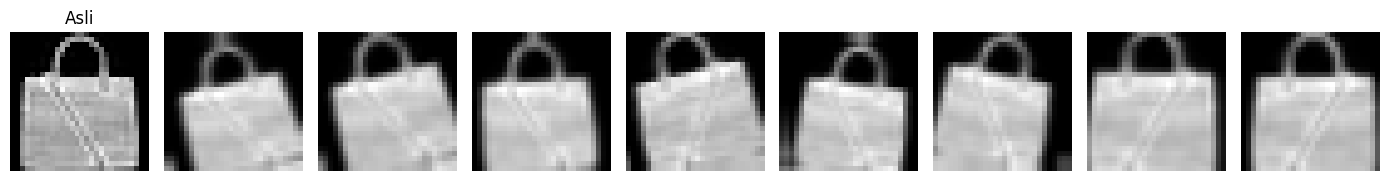

In [9]:
# 3.4 Augmentasi
def get_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),             # sekitar +/- 14 derajat
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
    ], name="augmentation")

aug_demo = get_augmentation()
sample = X_train[:1]
fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(sample[0, :, :, 0], cmap="gray"); axes[0].set_title("Asli"); axes[0].axis("off")
for k in range(1, 9):
    axes[k].imshow(aug_demo(sample, training=True)[0, :, :, 0], cmap="gray"); axes[k].axis("off")
plt.tight_layout(); plt.savefig("figures/04_augmentasi.png", dpi=150); plt.show()

## 3.5 Input pipeline dengan `tf.data`

**Apa itu `tf.data`?** API TensorFlow untuk membangun alur penyuplai data (*input pipeline*) ke model. Data diberikan sebagai objek `tf.data.Dataset` yang diproses bertahap.

| Langkah | Fungsi | Dipakai pada |
|---|---|---|
| 1. `from_tensor_slices((X, y))` | Memecah array menjadi pasangan (citra, label) per sampel | latih, validasi, uji |
| 2. `shuffle(buffer_size=N, seed=SEED, reshuffle_each_iteration=True)` | Mengacak urutan sampel dan mengacak ulang setiap epoch, agar model tidak menghafal urutan dan hasil bisa direproduksi | **hanya latih** |
| 3. `batch(BATCH_SIZE)` | Mengelompokkan sampel menjadi batch berukuran 128 | latih, validasi, uji |
| 4. `prefetch(AUTOTUNE)` | Menyiapkan batch berikutnya selagi model memproses batch sekarang | latih, validasi, uji |

**Keputusan desain:**
- Data validasi dan uji **tidak diacak** agar urutan prediksi sama dengan urutan `y_val` dan `y_test` (dibutuhkan untuk confusion matrix dan classification report).
- Normalisasi (`Rescaling`) dan augmentasi berada **di dalam model**, bukan di `.map()`, supaya preprocessing saat training dan saat inferensi (aplikasi deployment) identik.
- `.cache()` tidak dipakai karena data sudah berada di memori.
- Dataset yang sama dipakai oleh MLP, CNN, dan MobileNetV2 agar perbandingan adil.

In [10]:
# 3.5a Membangun input pipeline tf.data
BATCH_SIZE = 128                 # jumlah citra per batch
AUTOTUNE = tf.data.AUTOTUNE      # biarkan TensorFlow memilih paralelisme/buffer yang optimal


def make_dataset(X, y, training):
    """Bangun pipeline tf.data dari array NumPy.
    X: (N, 28, 28, 1) float32 skala 0-255 | y: (N,) label integer | training: True -> data diacak."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, training=True)    # diacak
val_ds   = make_dataset(X_val,   y_val,   training=False)   # tidak diacak
test_ds  = make_dataset(X_test,  y_test,  training=False)   # tidak diacak

steps_per_epoch = int(np.ceil(len(X_train) / BATCH_SIZE))
print(f"Batch size: {BATCH_SIZE} | langkah per epoch (latih): {steps_per_epoch}")
print("Struktur elemen (element_spec):", train_ds.element_spec)

Batch size: 128 | langkah per epoch (latih): 422
Struktur elemen (element_spec): (TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.uint8, name=None))


Satu batch latih  : citra (128, 28, 28, 1) <dtype: 'float32'> | label (128,) <dtype: 'uint8'>
Jumlah sampel via pipeline -> latih: 54000, validasi: 6000, uji: 10000
Urutan label latih berbeda antar epoch : True
Urutan data validasi = urutan asli     : True
Urutan data uji = urutan asli          : True


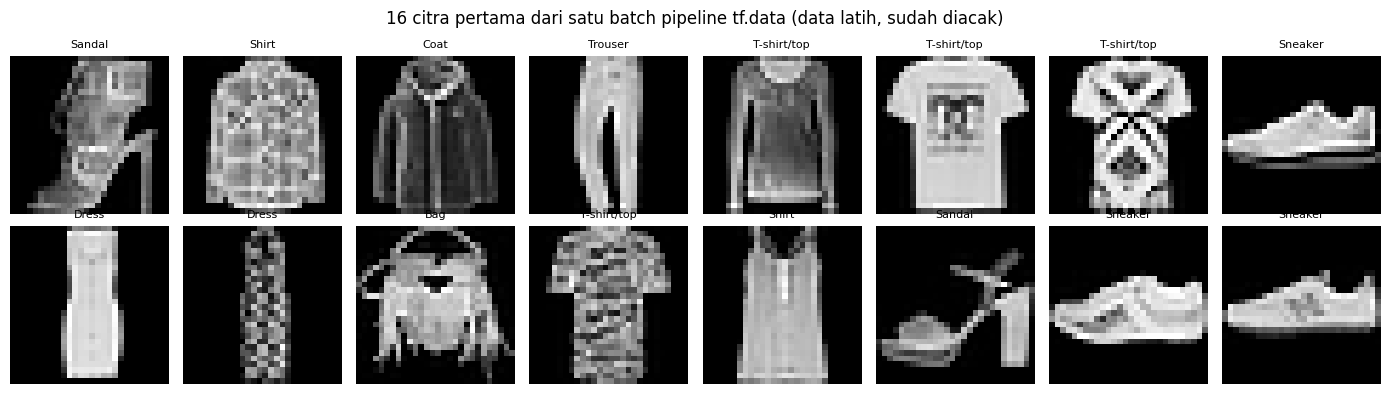

In [11]:
# 3.5b Pemeriksaan pipeline (hasilnya bisa dikutip di laporan)
xb, yb = next(iter(train_ds))
print("Satu batch latih  : citra", xb.shape, xb.dtype, "| label", yb.shape, yb.dtype)

n_train = sum(int(y.shape[0]) for _, y in train_ds)
n_val   = sum(int(y.shape[0]) for _, y in val_ds)
n_test  = sum(int(y.shape[0]) for _, y in test_ds)
print(f"Jumlah sampel via pipeline -> latih: {n_train}, validasi: {n_val}, uji: {n_test}")
assert (n_train, n_val, n_test) == (len(X_train), len(X_val), len(X_test)), "Jumlah sampel tidak cocok!"

order_epoch1 = np.concatenate([y.numpy() for _, y in train_ds.take(5)])
order_epoch2 = np.concatenate([y.numpy() for _, y in train_ds.take(5)])
print("Urutan label latih berbeda antar epoch :", not np.array_equal(order_epoch1, order_epoch2))
print("Urutan data validasi = urutan asli     :", np.array_equal(np.concatenate([y.numpy() for _, y in val_ds]), y_val))
print("Urutan data uji = urutan asli          :", np.array_equal(np.concatenate([y.numpy() for _, y in test_ds]), y_test))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), xb.numpy(), yb.numpy()):
    ax.imshow(img[:, :, 0], cmap="gray"); ax.set_title(CLASS_NAMES[lab], fontsize=8); ax.axis("off")
plt.suptitle("16 citra pertama dari satu batch pipeline tf.data (data latih, sudah diacak)")
plt.tight_layout(); plt.savefig("figures/04b_batch_tfdata.png", dpi=150); plt.show()

## 4. Arsitektur model

Tiga keluarga model dibangun pada data yang sama agar perbandingannya adil:

| Model | Peran | Alasan |
|---|---|---|
| MLP (DNN) | Baseline | Memperlihatkan batas kemampuan jaringan yang memperlakukan piksel sebagai vektor datar tanpa struktur spasial |
| CNN buatan sendiri | Kandidat model final | Konvolusi menangkap pola lokal (tepi, tekstur, bentuk kerah/lengan), hemat parameter, dan mendukung Grad-CAM |
| MobileNetV2 (transfer learning) | Pembanding | Menguji apakah fitur dari ImageNet membantu pada citra kecil 28x28 yang di-upscale |

Konfigurasi dasar CNN: blok konvolusi (2x Conv 3x3 + BatchNorm + ReLU, lalu MaxPooling + Dropout) dengan filter 32, 64, 128, dilanjutkan Flatten, Dense 128 (ReLU), Dropout, dan Softmax 10 kelas. Optimizer Adam (lr 1e-3), loss sparse categorical crossentropy. **Pilihan akhir (komponen mana yang dipakai) ditentukan oleh hasil eksperimen pada bagian 7, bukan ditetapkan lebih dulu.**

In [12]:
def build_mlp(name="MLP_baseline"):
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)


def conv_block(x, filters, use_bn, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=not use_bn)(x)
        if use_bn:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    if drop > 0:
        x = layers.Dropout(drop / 2)(x)
    return x


def build_cnn(use_bn=True, dropout=0.3, augment=True, filters=(32, 64, 128), name="CNN"):
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Rescaling(1.0 / 255)(inputs)
    if augment:
        x = get_augmentation()(x)
    for f in filters:
        x = conv_block(x, f, use_bn, dropout)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)


def build_transfer(img_size=96, name="MobileNetV2_TL"):
    inputs = keras.Input(shape=(28, 28, 1))
    x = get_augmentation()(inputs)
    x = layers.Resizing(img_size, img_size)(x)            # 28x28 -> 96x96
    x = layers.Concatenate()([x, x, x])                    # 1 channel -> 3 channel
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)        # skala [-1, 1] sesuai MobileNetV2
    base = keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3), include_top=False, weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), base


build_cnn(name="CNN_contoh").summary()

Model: "CNN_contoh"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 436,650 (1.67 MB)

 Trainable params: 435,754 (1.66 MB)

 Non-trainable params: 896 (3.50 KB)

## 5. Fungsi pelatihan

Semua model dilatih dengan prosedur yang sama dan membaca data lewat pipeline `tf.data`: batch size 128, maksimal 25 epoch, `EarlyStopping` pada val_loss (patience 4, bobot terbaik dipulihkan) dan `ReduceLROnPlateau`. Eksperimen inti diulang pada beberapa seed (variasi berasal dari inisialisasi bobot, dropout, dan augmentasi) sehingga perbedaan antarvarian dilaporkan sebagai rata-rata dan simpangan baku, bukan satu angka.

In [13]:
RUNS = []                                   # satu baris per run pelatihan
HISTORIES, PREDS, MODELS = {}, {}, {}       # kunci: (nama_model, seed)
MAX_EPOCHS = 25


def compile_model(model, optimizer="adam", lr=1e-3):
    opt = keras.optimizers.Adam(lr) if optimizer == "adam" else keras.optimizers.SGD(lr, momentum=0.9)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])


def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]


def run_fit(model, epochs=MAX_EPOCHS):
    # Ukuran batch sudah ditentukan di dalam dataset (.batch), jadi argumen batch_size tidak boleh diberikan.
    return model.fit(train_ds, validation_data=val_ds, shuffle=False,
                     epochs=epochs, callbacks=get_callbacks(), verbose=2)


def merge_histories(hists):
    merged = {}
    for h in hists:
        for k, v in h.history.items():
            merged.setdefault(k, []).extend(v)
    return merged


def record(name, seed, model, hists, seconds, optimizer="adam", lr=1e-3):
    _, val_acc = model.evaluate(val_ds, verbose=0)
    y_pred_ = model.predict(test_ds, verbose=0).argmax(axis=1)   # test_ds tidak diacak -> urutan = y_test
    merged = merge_histories(hists)
    RUNS.append({
        "model": name, "seed": seed,
        "parameter": model.count_params(), "optimizer": optimizer, "lr": lr,
        "epoch": len(merged["loss"]), "waktu_latih_detik": round(seconds, 1),
        "val_acc": round(float(val_acc), 4),
        "test_acc": round(float(accuracy_score(y_test, y_pred_)), 4),
        "test_macro_f1": round(float(f1_score(y_test, y_pred_, average="macro")), 4),
    })
    HISTORIES[(name, seed)], PREDS[(name, seed)], MODELS[(name, seed)] = merged, y_pred_, model
    r = RUNS[-1]
    print(f"\n>> {name} (seed {seed}): val_acc={r['val_acc']}  test_acc={r['test_acc']}  "
          f"macro_f1={r['test_macro_f1']}  ({seconds:.0f} detik)")


def train_cnn_variant(name, cfg, seed, optimizer="adam", lr=1e-3):
    keras.utils.set_random_seed(seed)
    m = build_cnn(name=f"{name}_s{seed}", **cfg)
    compile_model(m, optimizer=optimizer, lr=lr)
    t0 = time.time()
    h = run_fit(m)
    record(name, seed, m, [h], time.time() - t0, optimizer, lr)


def summarize_runs():
    df = pd.DataFrame(RUNS)
    agg = df.groupby("model", sort=False).agg(
        n_run=("seed", "count"), parameter=("parameter", "first"),
        optimizer=("optimizer", "first"), lr=("lr", "first"),
        epoch_rata2=("epoch", "mean"), waktu_detik_rata2=("waktu_latih_detik", "mean"),
        val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
        test_acc_mean=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
        f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
    ).fillna(0.0)
    return df, agg.round(4)

## 6. Model 1 - MLP (DNN baseline)

In [14]:
for s in SEEDS:
    keras.utils.set_random_seed(s)
    mlp = build_mlp(name=f"MLP_baseline_s{s}")
    compile_model(mlp)
    t0 = time.time()
    h = run_fit(mlp)
    record("MLP_baseline", s, mlp, [h], time.time() - t0)

Epoch 1/25
422/422 - 7s - 15ms/step - accuracy: 0.8169 - loss: 0.5233 - val_accuracy: 0.8608 - val_loss: 0.3917 - learning_rate: 0.0010
Epoch 2/25
422/422 - 1s - 3ms/step - accuracy: 0.8648 - loss: 0.3747 - val_accuracy: 0.8717 - val_loss: 0.3569 - learning_rate: 0.0010
Epoch 3/25
422/422 - 1s - 3ms/step - accuracy: 0.8775 - loss: 0.3345 - val_accuracy: 0.8800 - val_loss: 0.3290 - learning_rate: 0.0010
Epoch 4/25
422/422 - 1s - 3ms/step - accuracy: 0.8857 - loss: 0.3097 - val_accuracy: 0.8877 - val_loss: 0.3091 - learning_rate: 0.0010
Epoch 5/25
422/422 - 1s - 3ms/step - accuracy: 0.8924 - loss: 0.2906 - val_accuracy: 0.8827 - val_loss: 0.3214 - learning_rate: 0.0010
Epoch 6/25
422/422 - 1s - 3ms/step - accuracy: 0.8978 - loss: 0.2770 - val_accuracy: 0.8897 - val_loss: 0.3012 - learning_rate: 0.0010
Epoch 7/25
422/422 - 1s - 3ms/step - accuracy: 0.9035 - loss: 0.2612 - val_accuracy: 0.8980 - val_loss: 0.2807 - learning_rate: 0.0010
Epoch 8/25
422/422 - 1s - 3ms/step - accuracy: 0.9062 

## 7. Model 2 - CNN, studi ablasi, dan eksperimen hyperparameter

**Ablasi inti** (diulang pada semua `SEEDS`): empat varian CNN dilatih bertahap untuk mengukur kontribusi tiap komponen, yaitu BatchNorm, Dropout, dan augmentasi.

**Eksperimen tambahan** (satu seed): optimizer SGD+momentum, kedalaman jaringan (2 blok vs 3 blok), dan learning rate yang lebih kecil. Ini menjadi bukti untuk pilihan jumlah layer, optimizer, dan hyperparameter di laporan.

Model final dipilih **otomatis** dari ablasi inti berdasarkan **rata-rata akurasi validasi tertinggi** (lihat bagian 9b), sehingga justifikasi di laporan mengikuti hasil, bukan sebaliknya.

In [15]:
CFG_D = dict(use_bn=True, dropout=0.3, augment=True)

CORE_VARIANTS = [
    ("CNN_A_polos",          dict(use_bn=False, dropout=0.0, augment=False)),
    ("CNN_B_BN",             dict(use_bn=True,  dropout=0.0, augment=False)),
    ("CNN_C_BN_Dropout",     dict(use_bn=True,  dropout=0.3, augment=False)),
    ("CNN_D_BN_Dropout_Aug", CFG_D),
]
for name, cfg in CORE_VARIANTS:
    for s in SEEDS:
        train_cnn_variant(name, cfg, s)

Epoch 1/25
422/422 - 34s - 81ms/step - accuracy: 0.7981 - loss: 0.5463 - val_accuracy: 0.8838 - val_loss: 0.3199 - learning_rate: 0.0010
Epoch 2/25
422/422 - 5s - 11ms/step - accuracy: 0.8901 - loss: 0.3000 - val_accuracy: 0.9090 - val_loss: 0.2553 - learning_rate: 0.0010
Epoch 3/25
422/422 - 4s - 10ms/step - accuracy: 0.9076 - loss: 0.2488 - val_accuracy: 0.9150 - val_loss: 0.2331 - learning_rate: 0.0010
Epoch 4/25
422/422 - 4s - 10ms/step - accuracy: 0.9219 - loss: 0.2120 - val_accuracy: 0.9212 - val_loss: 0.2202 - learning_rate: 0.0010
Epoch 5/25
422/422 - 4s - 11ms/step - accuracy: 0.9322 - loss: 0.1862 - val_accuracy: 0.9285 - val_loss: 0.1980 - learning_rate: 0.0010
Epoch 6/25
422/422 - 4s - 10ms/step - accuracy: 0.9388 - loss: 0.1637 - val_accuracy: 0.9293 - val_loss: 0.1934 - learning_rate: 0.0010
Epoch 7/25
422/422 - 4s - 10ms/step - accuracy: 0.9460 - loss: 0.1462 - val_accuracy: 0.9308 - val_loss: 0.1927 - learning_rate: 0.0010
Epoch 8/25
422/422 - 5s - 11ms/step - accuracy:

In [16]:
# Eksperimen tambahan (satu seed): optimizer, kedalaman, learning rate
EXTRA_VARIANTS = [
    ("CNN_D_SGD",     CFG_D,                                 "sgd",  1e-2),
    ("CNN_D_2blok",   dict(CFG_D, filters=(32, 64)),         "adam", 1e-3),
    ("CNN_D_lr3e-4",  CFG_D,                                 "adam", 3e-4),
]
for name, cfg, opt, lr in EXTRA_VARIANTS:
    train_cnn_variant(name, cfg, SEEDS[0], optimizer=opt, lr=lr)

Epoch 1/25
422/422 - 12s - 29ms/step - accuracy: 0.7249 - loss: 0.7423 - val_accuracy: 0.7375 - val_loss: 0.7301 - learning_rate: 0.0100
Epoch 2/25
422/422 - 9s - 21ms/step - accuracy: 0.8038 - loss: 0.5229 - val_accuracy: 0.8100 - val_loss: 0.4994 - learning_rate: 0.0100
Epoch 3/25
422/422 - 9s - 22ms/step - accuracy: 0.8256 - loss: 0.4674 - val_accuracy: 0.8500 - val_loss: 0.4214 - learning_rate: 0.0100
Epoch 4/25
422/422 - 9s - 22ms/step - accuracy: 0.8440 - loss: 0.4228 - val_accuracy: 0.8850 - val_loss: 0.3108 - learning_rate: 0.0100
Epoch 5/25
422/422 - 9s - 22ms/step - accuracy: 0.8542 - loss: 0.3966 - val_accuracy: 0.8787 - val_loss: 0.3330 - learning_rate: 0.0100
Epoch 6/25
422/422 - 9s - 21ms/step - accuracy: 0.8606 - loss: 0.3786 - val_accuracy: 0.8797 - val_loss: 0.3268 - learning_rate: 0.0100
Epoch 7/25
422/422 - 9s - 22ms/step - accuracy: 0.8733 - loss: 0.3433 - val_accuracy: 0.8948 - val_loss: 0.2786 - learning_rate: 0.0050
Epoch 8/25
422/422 - 9s - 22ms/step - accuracy:

## 8. Model 3 - Transfer learning (MobileNetV2)

Dua tahap: (1) *feature extraction*, hanya head baru yang dilatih sementara MobileNetV2 dibekukan; (2) *fine-tuning*, 30 layer terakhir MobileNetV2 dibuka dengan learning rate kecil (1e-4). Citra 28x28 di-upscale ke 96x96 dan diduplikasi ke 3 channel karena MobileNetV2 dilatih pada citra RGB. Model ini dilatih satu seed karena lebih mahal.

In [17]:
s = SEEDS[0]
keras.utils.set_random_seed(s)
tl_model, tl_base = build_transfer(name=f"MobileNetV2_TL_s{s}")
t0 = time.time()

# Tahap 1: latih head saja
compile_model(tl_model, lr=1e-3)
h1 = run_fit(tl_model, epochs=6)

# Tahap 2: fine-tuning 30 layer terakhir
tl_base.trainable = True
for layer in tl_base.layers[:-30]:
    layer.trainable = False
compile_model(tl_model, lr=1e-4)
h2 = run_fit(tl_model, epochs=10)

record("MobileNetV2_TL", s, tl_model, [h1, h2], time.time() - t0)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
422/422 - 27s - 63ms/step - accuracy: 0.7612 - loss: 0.6702 - val_accuracy: 0.8088 - val_loss: 0.4979 - learning_rate: 0.0010
Epoch 2/6
422/422 - 19s - 45ms/step - accuracy: 0.8280 - loss: 0.4716 - val_accuracy: 0.8192 - val_loss: 0.4701 - learning_rate: 0.0010
Epoch 3/6
422/422 - 19s - 45ms/step - accuracy: 0.8383 - loss: 0.4495 - val_accuracy: 0.8418 - val_loss: 0.4215 - learning_rate: 0.0010
Epoch 4/6
422/422 - 19s - 44ms/step - accuracy: 0.8395 - loss: 0.4379 - val_accuracy: 0.8287 - val_loss: 0.4474 - learning_rate: 0.0010
Epoch 5/6
422/422 - 19s - 45ms/step - accuracy: 0.8417 - loss: 0.4321 - val_accuracy: 0.8423 - val_loss: 0.4311 - learning_rate: 0.0010
Epoch 6/6
422/422 - 19s - 44ms/step - accuracy: 0.8468 - loss: 0.4154 - val_accuracy: 0.8407 - val_loss: 0.4221 - learning_rate: 5.0000e-04
Epoch 1/10
422/422 - 41s - 97ms/step - accuracy: 0.8398 - loss: 0.4749 - val_accuracy: 0.8608 - val_loss: 0.3953 - learning_rate: 1

## 9. Perbandingan model dan pemilihan model final

Pemilihan model memakai **akurasi validasi**, bukan akurasi uji, agar data uji tetap menjadi estimasi yang jujur. Akurasi uji hanya dilaporkan.

,n_run,parameter,optimizer,lr,epoch_rata2,waktu_detik_rata2,val_acc_mean,val_acc_std,test_acc_mean,test_acc_std,f1_mean,f1_std
model,,,,,,,,,,,,
MLP_baseline,3,235146,adam,0.0010,17.3333,27.2000,0.9067,0.0020,0.8930,0.0045,0.8927,0.0042
CNN_A_polos,3,435306,adam,0.0010,12.3333,69.8000,0.9339,0.0049,0.9256,0.0022,0.9255,0.0025
CNN_B_BN,3,436650,adam,0.0010,10.3333,66.2333,0.9346,0.0019,0.9254,0.0031,0.9248,0.0030
CNN_C_BN_Dropout,3,436650,adam,0.0010,18.3333,109.9667,0.9464,0.0006,0.9370,0.0024,0.9367,0.0025
CNN_D_BN_Dropout_Aug,3,436650,adam,0.0010,23.3333,242.7667,0.9321,0.0010,0.9210,0.0021,0.9210,0.0023
CNN_D_SGD,1,436650,sgd,0.0100,25.0000,232.6000,0.9223,0.0000,0.9127,0.0000,0.9122,0.0000
CNN_D_2blok,1,468394,adam,0.0010,25.0000,216.1000,0.9195,0.0000,0.9139,0.0000,0.9140,0.0000
CNN_D_lr3e-4,1,436650,adam,0.0003,25.0000,258.6000,0.9250,0.0000,0.9148,0.0000,0.9150,0.0000
MobileNetV2_TL,1,2270794,adam,0.0010,16.0000,454.9000,0.9107,0.0000,0.9046,0.0000,0.9044,0.0000


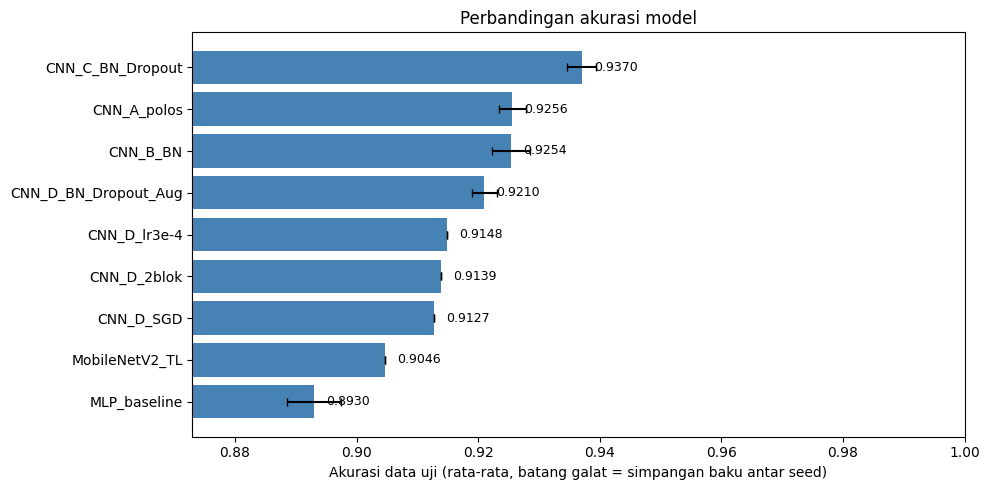

In [18]:
runs_df, agg = summarize_runs()
runs_df.to_csv("outputs/hasil_per_run.csv", index=False)
agg.to_csv("outputs/perbandingan_model.csv")
display(agg)

order = agg.sort_values("test_acc_mean")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(order.index, order["test_acc_mean"], xerr=order["test_acc_std"], color="steelblue", capsize=3)
ax.set_xlim(order["test_acc_mean"].min() - 0.02, 1.0)
ax.set_xlabel("Akurasi data uji (rata-rata, batang galat = simpangan baku antar seed)")
ax.set_title("Perbandingan akurasi model")
for i, v in enumerate(order["test_acc_mean"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig("figures/05_perbandingan_akurasi.png", dpi=150); plt.show()

### 9b. Pemilihan model final

Kriteria: **rata-rata akurasi validasi tertinggi** di antara varian ablasi inti (A-D). Dari varian terpilih, dipakai run dengan akurasi validasi tertinggi. Varian tambahan (SGD, 2 blok, lr kecil) dan MobileNetV2 dibandingkan sebagai pembanding; bila ada yang lebih tinggi secara berarti, selisihnya dibahas sebagai trade-off (akurasi vs ukuran/kecepatan/kemudahan penjelasan) di laporan.

In [19]:
core_names = [n for n, _ in CORE_VARIANTS]
ranking = agg.loc[core_names].sort_values("val_acc_mean", ascending=False)
display(ranking[["n_run", "parameter", "val_acc_mean", "val_acc_std", "test_acc_mean", "test_acc_std"]])

FINAL_NAME = ranking.index[0]
sub = runs_df[runs_df["model"] == FINAL_NAME].sort_values("val_acc")
FINAL_SEED = int(sub.iloc[-1]["seed"])
final_model = MODELS[(FINAL_NAME, FINAL_SEED)]
y_pred = PREDS[(FINAL_NAME, FINAL_SEED)]
final_row = runs_df[(runs_df["model"] == FINAL_NAME) & (runs_df["seed"] == FINAL_SEED)].iloc[0]

print(f"Model final (val_acc rata-rata tertinggi di ablasi inti): {FINAL_NAME}, seed run terpilih: {FINAL_SEED}")
print(f"  val_acc={final_row['val_acc']}  test_acc={final_row['test_acc']}  macro_f1={final_row['test_macro_f1']}")

best_val = ranking.loc[FINAL_NAME, "val_acc_mean"]
for n, r in agg.drop(index=core_names).iterrows():
    gap = r["val_acc_mean"] - best_val
    if gap > 0.003:
        print(f"Catatan: {n} punya akurasi validasi lebih tinggi {gap:+.4f} daripada model final. "
              f"Bahas sebagai trade-off di laporan (parameter: {int(r['parameter']):,} vs {int(ranking.loc[FINAL_NAME, 'parameter']):,}).")

,n_run,parameter,val_acc_mean,val_acc_std,test_acc_mean,test_acc_std
model,,,,,,
CNN_C_BN_Dropout,3,436650,0.9464,0.0006,0.9370,0.0024
CNN_B_BN,3,436650,0.9346,0.0019,0.9254,0.0031
CNN_A_polos,3,435306,0.9339,0.0049,0.9256,0.0022
CNN_D_BN_Dropout_Aug,3,436650,0.9321,0.0010,0.9210,0.0021


Model final (val_acc rata-rata tertinggi di ablasi inti): CNN_C_BN_Dropout, seed run terpilih: 44
  val_acc=0.947  test_acc=0.9375  macro_f1=0.9372


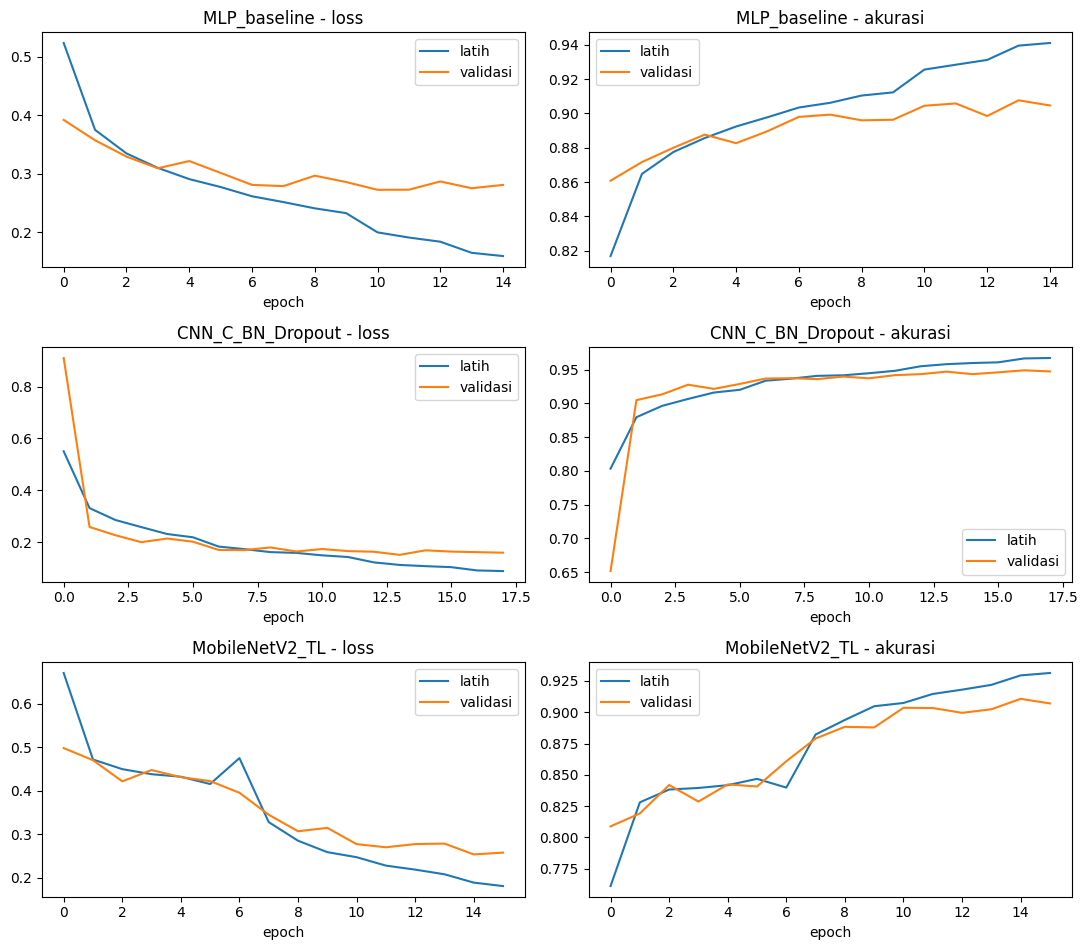

In [20]:
curve_models = [("MLP_baseline", SEEDS[0]), (FINAL_NAME, FINAL_SEED), ("MobileNetV2_TL", SEEDS[0])]
fig, axes = plt.subplots(len(curve_models), 2, figsize=(11, 3.2 * len(curve_models)))
for r, key in enumerate(curve_models):
    hist = HISTORIES[key]
    axes[r, 0].plot(hist["loss"], label="latih"); axes[r, 0].plot(hist["val_loss"], label="validasi")
    axes[r, 0].set_title(f"{key[0]} - loss"); axes[r, 0].legend()
    axes[r, 1].plot(hist["accuracy"], label="latih"); axes[r, 1].plot(hist["val_accuracy"], label="validasi")
    axes[r, 1].set_title(f"{key[0]} - akurasi"); axes[r, 1].legend()
    for c in range(2): axes[r, c].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("figures/06_kurva_pelatihan.png", dpi=150); plt.show()

## 10. Evaluasi model final dan analisis error

Data uji dipakai **sekali** untuk pelaporan akhir model final. Selain akurasi, dilaporkan precision/recall/F1 per kelas, confusion matrix, selang kepercayaan bootstrap, dan uji signifikansi terhadap baseline MLP.

In [21]:
print(f"Akurasi uji final: {final_row['test_acc']:.4f} | macro F1: {final_row['test_macro_f1']:.4f}\n")

report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0)
pd.DataFrame(report).T.to_csv("outputs/classification_report.csv")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

Akurasi uji final: 0.9375 | macro F1: 0.9372

              precision    recall  f1-score   support

 T-shirt/top     0.8760    0.9110    0.8931      1000
     Trouser     0.9910    0.9940    0.9925      1000
    Pullover     0.8986    0.9130    0.9058      1000
       Dress     0.9335    0.9410    0.9373      1000
        Coat     0.8990    0.9080    0.9035      1000
      Sandal     0.9940    0.9930    0.9935      1000
       Shirt     0.8332    0.7740    0.8025      1000
     Sneaker     0.9676    0.9850    0.9762      1000
         Bag     0.9950    0.9880    0.9915      1000
  Ankle boot     0.9837    0.9680    0.9758      1000

    accuracy                         0.9375     10000
   macro avg     0.9372    0.9375    0.9372     10000
weighted avg     0.9372    0.9375    0.9372     10000



In [22]:
# Selang kepercayaan bootstrap dan uji McNemar terhadap baseline MLP
correct = (y_pred == y_test)
rng = np.random.default_rng(SEED)
boot = np.array([correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(2000)])
ACC_CI = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
print(f"Akurasi uji model final: {correct.mean():.4f} (95% CI bootstrap: {ACC_CI[0]:.4f} - {ACC_CI[1]:.4f})")

MCNEMAR = None
try:
    from scipy.stats import binomtest
    mlp_pred = PREDS[("MLP_baseline", SEEDS[0])]
    b = int(((mlp_pred != y_test) & (y_pred == y_test)).sum())   # MLP salah, model final benar
    c = int(((mlp_pred == y_test) & (y_pred != y_test)).sum())   # MLP benar, model final salah
    p = float(binomtest(b, b + c, 0.5).pvalue) if (b + c) > 0 else 1.0
    MCNEMAR = {"mlp_salah_final_benar": b, "mlp_benar_final_salah": c, "p_value": p}
    print(f"McNemar vs MLP baseline: MLP salah & final benar = {b}, MLP benar & final salah = {c}, p-value = {p:.2e}")
except Exception as e:
    print("Uji McNemar dilewati:", type(e).__name__, e)

Akurasi uji model final: 0.9375 (95% CI bootstrap: 0.9325 - 0.9420)
McNemar vs MLP baseline: MLP salah & final benar = 656, MLP benar & final salah = 172, p-value = 2.77e-67


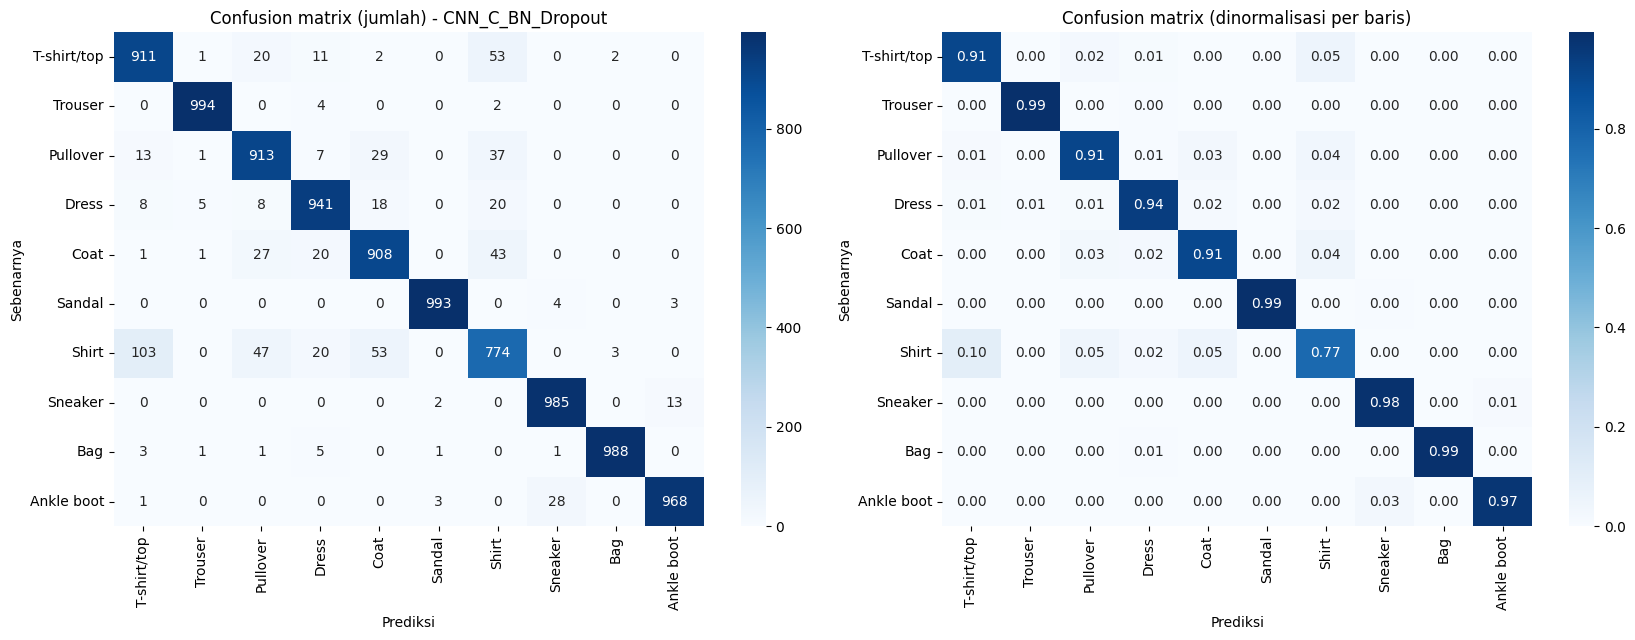

In [23]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title(f"Confusion matrix (jumlah) - {FINAL_NAME}"); ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Sebenarnya")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
ax[1].set_title("Confusion matrix (dinormalisasi per baris)"); ax[1].set_xlabel("Prediksi"); ax[1].set_ylabel("Sebenarnya")
plt.tight_layout(); plt.savefig("figures/07_confusion_matrix.png", dpi=150); plt.show()

Lima kesalahan terbanyak:


,kelas_sebenarnya,diprediksi_sebagai,jumlah
25,Shirt,T-shirt/top,103
28,Shirt,Coat,53
4,T-shirt/top,Shirt,53
26,Shirt,Pullover,47
22,Coat,Shirt,43


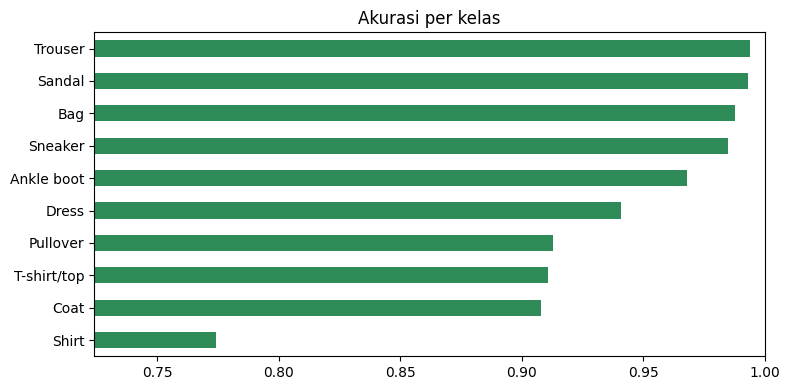

Kelas tersulit : Shirt (0.774)
Kelas termudah : Trouser (0.994)


In [24]:
# Pasangan kelas yang paling sering tertukar
pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            pairs.append((CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])))
pairs_df = pd.DataFrame(pairs, columns=["kelas_sebenarnya", "diprediksi_sebagai", "jumlah"]).sort_values("jumlah", ascending=False)
pairs_df.to_csv("outputs/pasangan_kelas_tertukar.csv", index=False)
print("Lima kesalahan terbanyak:")
display(pairs_df.head(5))

# Akurasi per kelas
per_class = pd.Series(np.diag(cm) / cm.sum(axis=1), index=CLASS_NAMES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
per_class.plot(kind="barh", ax=ax, color="seagreen")
ax.set_xlim(per_class.min() - 0.05, 1.0); ax.set_title("Akurasi per kelas")
plt.tight_layout(); plt.savefig("figures/08_akurasi_per_kelas.png", dpi=150); plt.show()
print("Kelas tersulit :", per_class.index[0], f"({per_class.iloc[0]:.3f})")
print("Kelas termudah :", per_class.index[-1], f"({per_class.iloc[-1]:.3f})")

Jumlah salah prediksi: 625 dari 10000
Rata-rata keyakinan saat benar: 0.973 | saat salah: 0.735


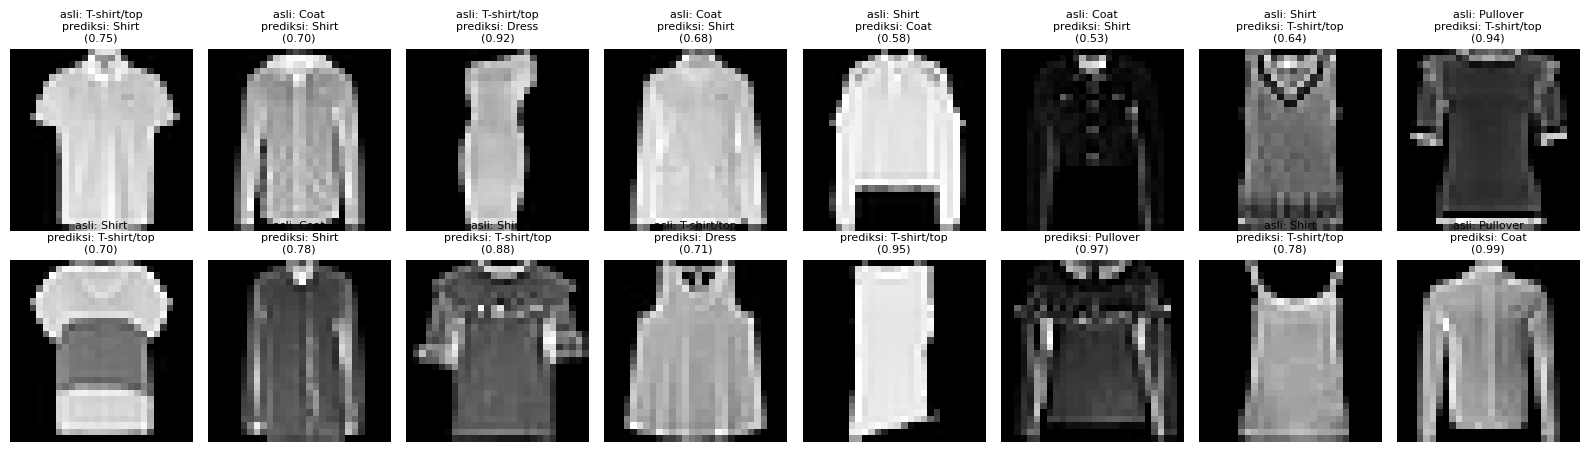

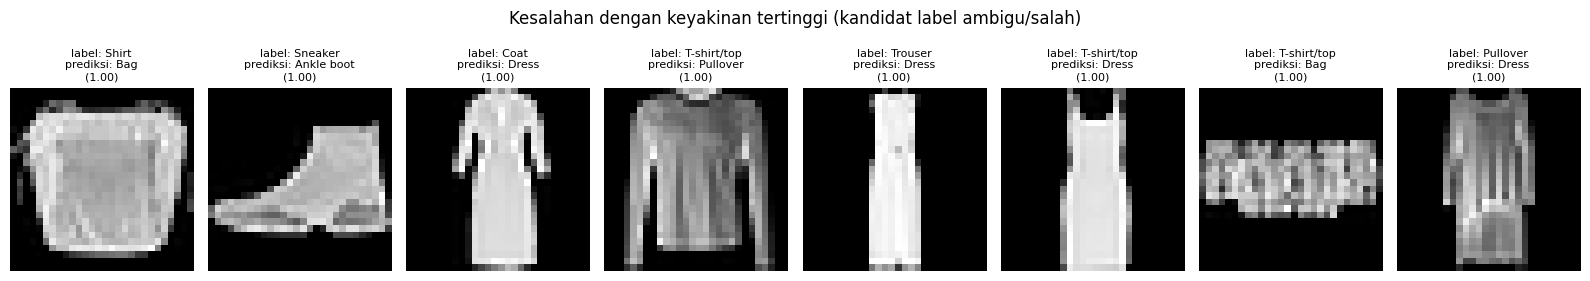

In [25]:
# Contoh citra yang salah prediksi beserta tingkat keyakinan model
probs = final_model.predict(test_ds, verbose=0)   # urutan sama dengan y_test karena test_ds tidak diacak
wrong = np.where(y_pred != y_test)[0]
conf = probs.max(axis=1)
print(f"Jumlah salah prediksi: {len(wrong)} dari {len(y_test)}")
print(f"Rata-rata keyakinan saat benar: {conf[y_pred == y_test].mean():.3f} | saat salah: {conf[wrong].mean():.3f}")

rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(16, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax in axes.ravel(): ax.axis("off")
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i, :, :, 0], cmap="gray")
    ax.set_title(f"asli: {CLASS_NAMES[y_test[i]]}\nprediksi: {CLASS_NAMES[y_pred[i]]}\n({conf[i]:.2f})", fontsize=8)
plt.tight_layout(); plt.savefig("figures/09_contoh_salah_prediksi.png", dpi=150); plt.show()

# Kesalahan dengan keyakinan tertinggi: kandidat citra ambigu atau berlabel salah
top_conf_wrong = wrong[np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, top_conf_wrong):
    ax.imshow(X_test[i, :, :, 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"label: {CLASS_NAMES[y_test[i]]}\nprediksi: {CLASS_NAMES[y_pred[i]]}\n({conf[i]:.2f})", fontsize=8)
plt.suptitle("Kesalahan dengan keyakinan tertinggi (kandidat label ambigu/salah)", y=1.08)
plt.tight_layout(); plt.savefig("figures/09b_salah_keyakinan_tinggi.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Detail arsitektur model final

Untuk inferensi, lapisan augmentasi dibuang (augmentasi hanya relevan saat training). Model hasilnya (`deploy_model`) memiliki bobot yang sama persis dan dipakai untuk Grad-CAM, konversi TFLite, dan aplikasi deployment. Tabel dan diagram di bawah mendukung poin arsitektur di laporan (jenis dan jumlah layer, ukuran output, jumlah parameter).

In [26]:
def strip_augmentation(model, name="deploy_model"):
    # Hanya untuk model berantai linear (MLP/CNN buatan sendiri), bukan transfer learning
    inp = keras.Input(shape=model.input_shape[1:])
    x = inp
    for layer in model.layers:
        if isinstance(layer, layers.InputLayer) or layer.name == "augmentation":
            continue
        x = layer(x)
    return keras.Model(inp, x, name=name)

assert FINAL_NAME.startswith("CNN"), "Grad-CAM dan strip_augmentation dirancang untuk CNN buatan sendiri"
deploy_model = strip_augmentation(final_model)

same = np.allclose(deploy_model.predict(X_test[:500], verbose=0),
                   final_model.predict(X_test[:500], verbose=0), atol=1e-5)
print("Prediksi deploy_model identik dengan model latih:", same)
print("Total parameter deploy_model:", f"{deploy_model.count_params():,}")

Prediksi deploy_model identik dengan model latih: True
Total parameter deploy_model: 436,650


In [27]:
rows = []
for l in deploy_model.layers:
    if isinstance(l, layers.InputLayer):
        continue
    try:
        shape = tuple(l.output.shape[1:])
    except Exception:
        shape = "-"
    rows.append({"layer": l.name, "tipe": l.__class__.__name__, "output_shape": str(shape), "parameter": l.count_params()})
arch_df = pd.DataFrame(rows)
arch_df.to_csv("outputs/tabel_arsitektur.csv", index=False)
display(arch_df)
print("Jumlah layer per tipe:")
print(arch_df["tipe"].value_counts().to_string())

,layer,tipe,output_shape,parameter
0,rescaling_13,Rescaling,"(28, 28, 1)",0
1,conv2d_54,Conv2D,"(28, 28, 32)",288
2,batch_normalization_36,BatchNormalization,"(28, 28, 32)",128
3,activation_54,Activation,"(28, 28, 32)",0
4,conv2d_55,Conv2D,"(28, 28, 32)",9216
5,batch_normalization_37,BatchNormalization,"(28, 28, 32)",128
6,activation_55,Activation,"(28, 28, 32)",0
7,max_pooling2d_27,MaxPooling2D,"(14, 14, 32)",0
8,dropout_12,Dropout,"(14, 14, 32)",0
9,conv2d_56,Conv2D,"(14, 14, 64)",18432


Jumlah layer per tipe:
tipe
Conv2D                6
BatchNormalization    6
Activation            6
Dropout               4
MaxPooling2D          3
Dense                 2
Rescaling             1
Flatten               1


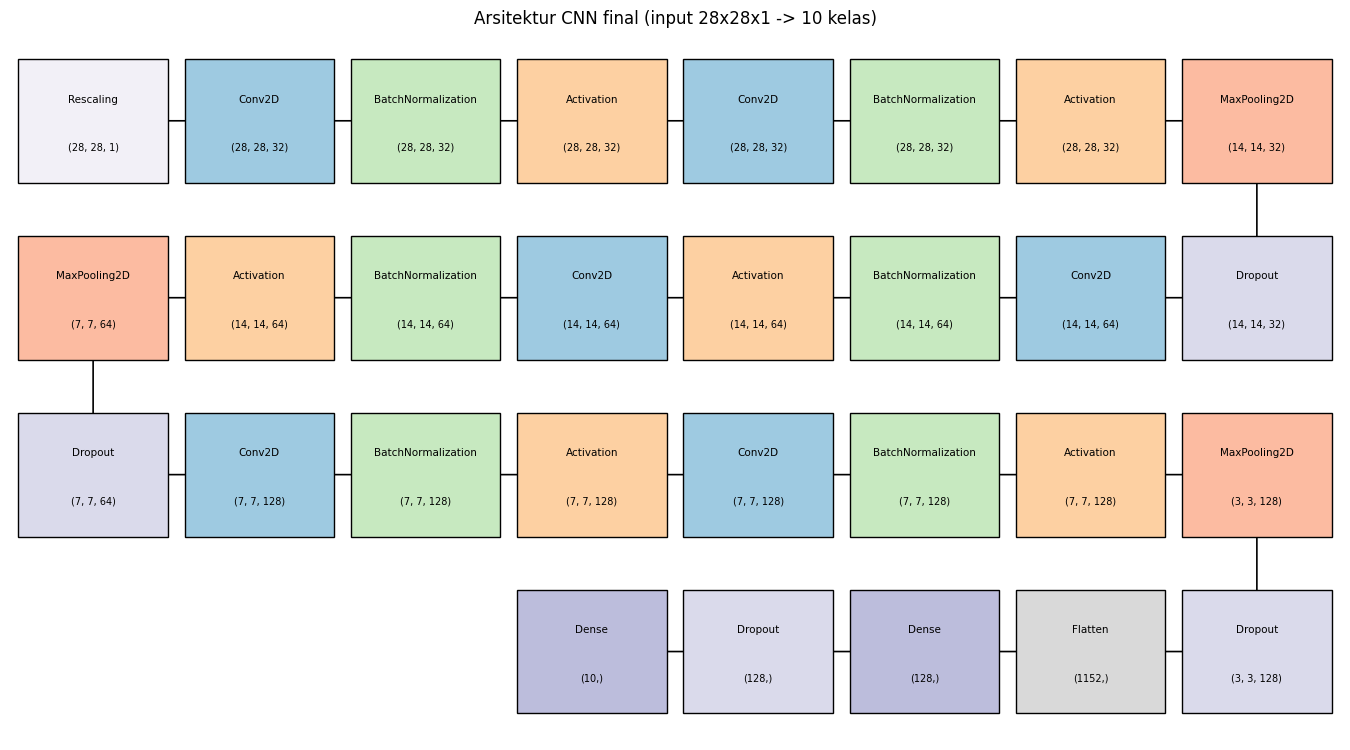

In [28]:
def draw_architecture(df, fname, per_row=8):
    colors = {"Rescaling": "#f2f0f7", "Conv2D": "#9ecae1", "BatchNormalization": "#c7e9c0",
              "Activation": "#fdd0a2", "MaxPooling2D": "#fcbba1", "Dropout": "#dadaeb",
              "Flatten": "#d9d9d9", "Dense": "#bcbddc"}
    items = list(zip(df["tipe"], df["output_shape"]))
    n = len(items)
    rows_n = int(np.ceil(n / per_row))
    fig, ax = plt.subplots(figsize=(per_row * 1.7, rows_n * 1.9))
    ax.set_xlim(0, per_row); ax.set_ylim(0, rows_n); ax.axis("off")

    def center(k):
        r, c = divmod(k, per_row)
        x = c if r % 2 == 0 else per_row - 1 - c      # susunan zig-zag
        return x + 0.5, rows_n - 1 - r + 0.5

    for k, (t, s) in enumerate(items):
        cx, cy = center(k)
        if k + 1 < n:
            nx, ny = center(k + 1)
            ax.annotate("", xy=(nx, ny), xytext=(cx, cy), arrowprops=dict(arrowstyle="->", lw=1.2), zorder=1)
        ax.add_patch(plt.Rectangle((cx - 0.45, cy - 0.35), 0.9, 0.7, color=colors.get(t, "#eeeeee"), ec="black", zorder=2))
        ax.text(cx, cy + 0.12, t, ha="center", va="center", fontsize=7.5, zorder=3)
        ax.text(cx, cy - 0.15, s, ha="center", va="center", fontsize=7, zorder=3)
    ax.set_title("Arsitektur CNN final (input 28x28x1 -> 10 kelas)")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

draw_architecture(arch_df, "figures/10_arsitektur_cnn.png")
try:
    keras.utils.plot_model(deploy_model, to_file="figures/10b_plot_model.png", show_shapes=True, dpi=70)
except Exception as e:
    print("plot_model dilewati (graphviz/pydot tidak tersedia):", type(e).__name__)

## 12. Fitur unik 1 - Grad-CAM (penjelasan prediksi)

**Apa:** peta panas yang menunjukkan area citra yang paling berpengaruh pada keputusan model.
**Mengapa dibutuhkan:** model deep learning bersifat black box. Grad-CAM membantu memeriksa apakah model melihat bagian pakaian yang relevan (bukan latar atau artefak) dan menjelaskan kenapa dua kelas mirip bisa tertukar.
**Implementasi:** gradien skor kelas terhadap keluaran lapisan konvolusi terakhir dirata-ratakan per channel sebagai bobot, dijumlahkan dengan peta fitur, di-ReLU, lalu di-upscale ke 28x28.
**Pengujian dampak:** (1) visualisasi kualitatif untuk prediksi benar dan salah, (2) uji kuantitatif *masking*: menutup 20% piksel yang paling disorot Grad-CAM dibandingkan menutup 20% piksel acak. **Laporkan apa yang benar-benar keluar**; bila penurunan akurasinya tidak lebih besar daripada acak, tulis apa adanya dan bahas keterbatasannya.

In [29]:
last_conv_name = [l.name for l in deploy_model.layers if isinstance(l, (layers.Conv2D, layers.Activation))][-1]
print("Lapisan target Grad-CAM:", last_conv_name)
_gin = keras.Input(shape=(28, 28, 1))
_x, _conv_out = _gin, None
for _l in deploy_model.layers:          # rangkai ulang graf agar keluaran lapisan konvolusi ikut terhubung
    if isinstance(_l, layers.InputLayer):
        continue
    _x = _l(_x)
    if _l.name == last_conv_name:
        _conv_out = _x
grad_model = keras.Model(_gin, [_conv_out, _x])


def gradcam_batch(x, class_idx=None):
    """x: (B,28,28,1) skala 0-255. class_idx: None = kelas prediksi, atau array kelas per sampel."""
    x = tf.convert_to_tensor(x, dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x, training=False)
        if class_idx is None:
            score = tf.reduce_max(preds, axis=1)
        else:
            score = tf.gather(preds, tf.constant(np.asarray(class_idx), tf.int32), batch_dims=1)
        total = tf.reduce_sum(score)
    grads = tape.gradient(total, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(conv_out * weights, axis=-1, keepdims=True))
    cam = tf.image.resize(cam, (28, 28), method="bilinear")[..., 0]
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    return cam.numpy()


def overlay(ax, img, cam, title=""):
    ax.imshow(img[:, :, 0], cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=8); ax.axis("off")

Lapisan target Grad-CAM: activation_59


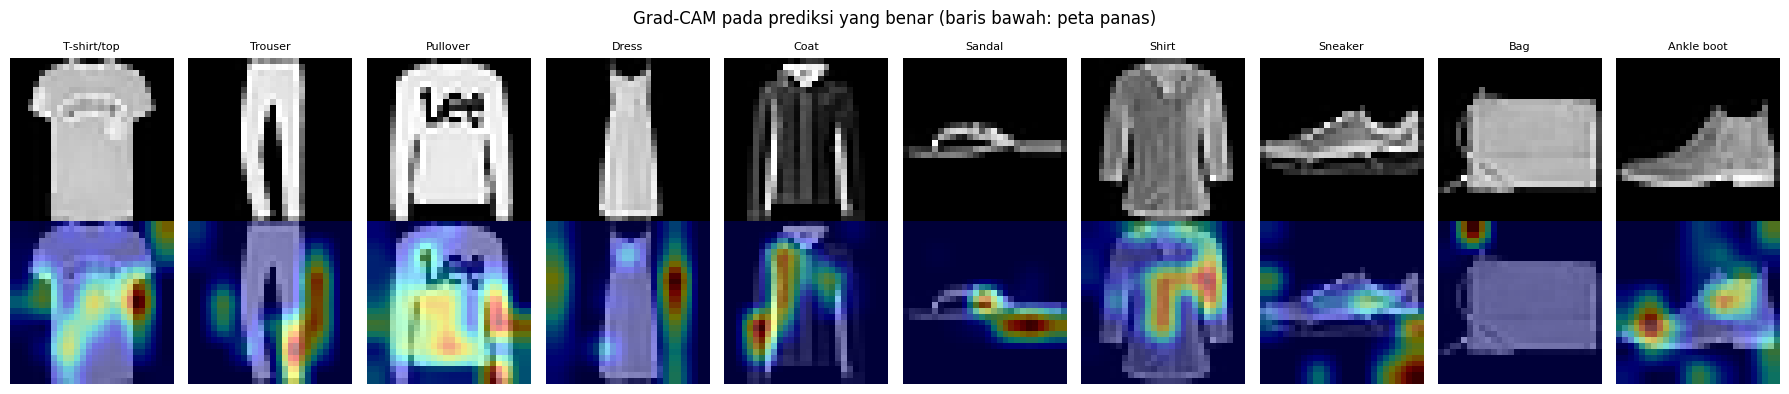

In [30]:
# (a) Satu contoh benar per kelas
def first_correct(c):
    ok = np.where((y_test == c) & (y_pred == c))[0]
    return ok[0] if len(ok) else np.where(y_test == c)[0][0]

correct_idx = [first_correct(c) for c in range(10)]
cams = gradcam_batch(X_test[correct_idx])
fig, axes = plt.subplots(2, 10, figsize=(18, 4))
for k, i in enumerate(correct_idx):
    axes[0, k].imshow(X_test[i, :, :, 0], cmap="gray"); axes[0, k].axis("off"); axes[0, k].set_title(CLASS_NAMES[y_test[i]], fontsize=8)
    overlay(axes[1, k], X_test[i], cams[k])
plt.suptitle("Grad-CAM pada prediksi yang benar (baris bawah: peta panas)")
plt.tight_layout(); plt.savefig("figures/11_gradcam_benar.png", dpi=150); plt.show()

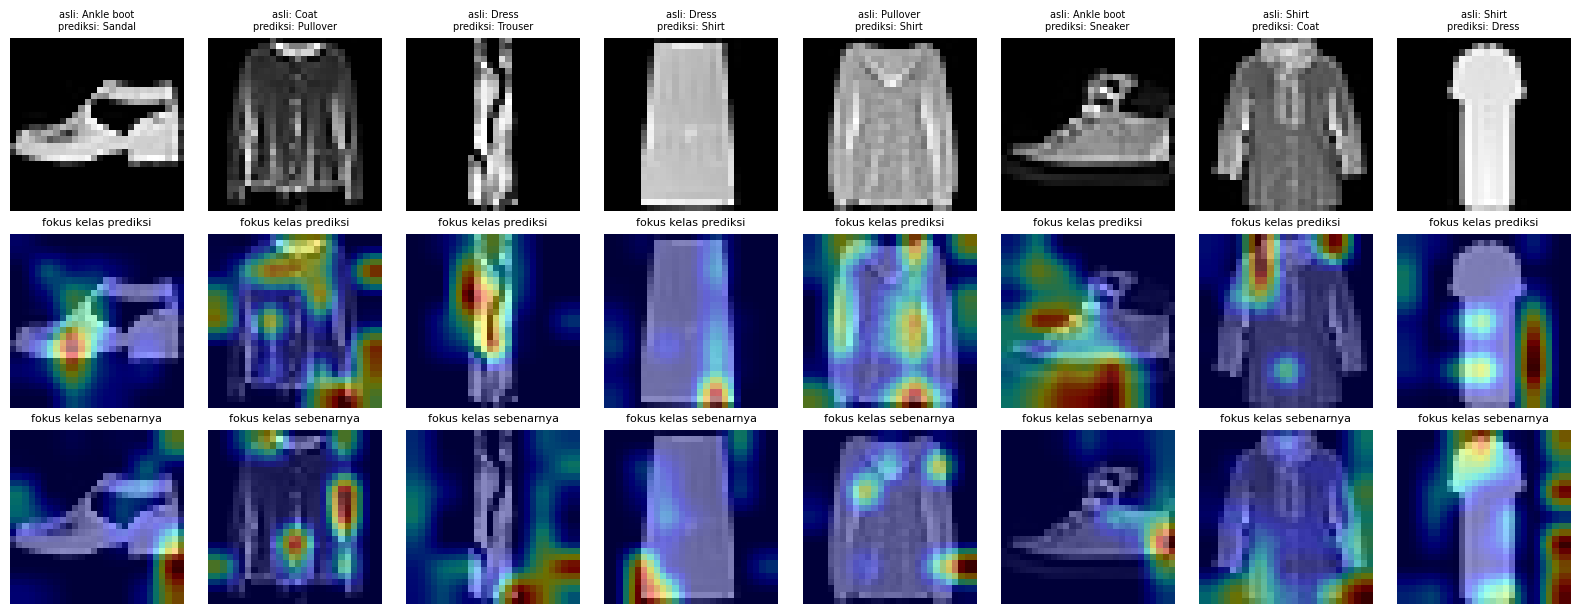

In [31]:
# (b) Contoh salah prediksi: peta panas untuk kelas prediksi (salah) vs kelas sebenarnya
idx = wrong[:8]
cam_pred = gradcam_batch(X_test[idx], class_idx=y_pred[idx])
cam_true = gradcam_batch(X_test[idx], class_idx=y_test[idx])
fig, axes = plt.subplots(3, len(idx), figsize=(2 * len(idx), 6.2))
for k, i in enumerate(idx):
    axes[0, k].imshow(X_test[i, :, :, 0], cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"asli: {CLASS_NAMES[y_test[i]]}\nprediksi: {CLASS_NAMES[y_pred[i]]}", fontsize=7)
    overlay(axes[1, k], X_test[i], cam_pred[k], "fokus kelas prediksi")
    overlay(axes[2, k], X_test[i], cam_true[k], "fokus kelas sebenarnya")
plt.tight_layout(); plt.savefig("figures/12_gradcam_salah_prediksi.png", dpi=150); plt.show()

,skenario,akurasi
0,Tanpa masking,0.944
1,Mask 20% piksel terpenting (Grad-CAM),0.707
2,Mask 20% piksel acak,0.800


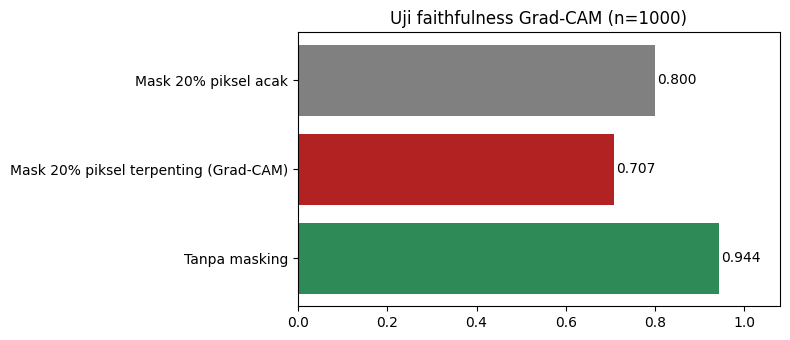

Hasil: masking Grad-CAM LEBIH merusak daripada masking acak (0.707 vs 0.800). Tulis kesimpulan di laporan sesuai hasil ini.


In [32]:
# (c) Uji kuantitatif masking: Grad-CAM vs acak
n = min(1000, len(X_test))
frac, k = 0.2, int(28 * 28 * 0.2)
rng = np.random.default_rng(SEED)
sel = rng.choice(len(X_test), n, replace=False)
xs, ys = X_test[sel], y_test[sel]

cam = gradcam_batch(xs).reshape(n, -1)
top_idx = np.argsort(-cam, axis=1)[:, :k]
rand_idx = np.argsort(rng.random((n, 28 * 28)), axis=1)[:, :k]

def masked_acc(idx_mat):
    xm = xs.reshape(n, -1).copy()
    np.put_along_axis(xm, idx_mat, 0.0, axis=1)
    return float((deploy_model.predict(xm.reshape(n, 28, 28, 1), verbose=0).argmax(1) == ys).mean())

acc_clean = float((deploy_model.predict(xs, verbose=0).argmax(1) == ys).mean())
gradcam_eval = pd.DataFrame({
    "skenario": ["Tanpa masking", "Mask 20% piksel terpenting (Grad-CAM)", "Mask 20% piksel acak"],
    "akurasi": [acc_clean, masked_acc(top_idx), masked_acc(rand_idx)],
}).round(4)
gradcam_eval.to_csv("outputs/gradcam_uji_masking.csv", index=False)
display(gradcam_eval)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(gradcam_eval["skenario"], gradcam_eval["akurasi"], color=["seagreen", "firebrick", "gray"])
for i, v in enumerate(gradcam_eval["akurasi"]): ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08); ax.set_title(f"Uji faithfulness Grad-CAM (n={n})")
plt.tight_layout(); plt.savefig("figures/13_gradcam_masking.png", dpi=150); plt.show()

gc, gr_ = gradcam_eval["akurasi"].iloc[1], gradcam_eval["akurasi"].iloc[2]
print("Hasil: masking Grad-CAM", "LEBIH merusak" if gc < gr_ else "TIDAK lebih merusak",
      f"daripada masking acak ({gc:.3f} vs {gr_:.3f}). Tulis kesimpulan di laporan sesuai hasil ini.")

## 13. Fitur unik 2 - Kompresi model ke TensorFlow Lite

**Apa:** model dikonversi ke format TFLite dengan dua jenis kuantisasi (dynamic range dan float16), lalu dibandingkan dengan model Keras asli.
**Mengapa dibutuhkan:** aplikasi web di hosting gratis (CPU, memori kecil) membutuhkan model yang kecil dan cepat. Kuantisasi memperkecil ukuran file dan dapat mempercepat inferensi dengan risiko kecil pada akurasi.
**Implementasi:** `tf.lite.TFLiteConverter` dengan `Optimize.DEFAULT` (dynamic range) atau `supported_types=[float16]`.
**Pengujian dampak:** tabel perbandingan ukuran file, akurasi pada seluruh data uji, dan waktu inferensi per citra. Varian terkecil dengan penurunan akurasi tidak lebih dari 0,2 poin dipilih untuk deployment.

Saved artifact at '/tmp/tmp3pis0p_x'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_663')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133389846949776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846938256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13338984695

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmpay6t2izv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_663')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133389846949776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846938256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13338984695

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved artifact at '/tmp/tmpx6o29rml'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_663')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133389846949776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846938256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846949200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846950544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133389846951696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13338984695

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,ukuran_KB,test_acc,latensi_ms_per_citra
format,,,
Keras (.keras),1806.3,0.9375,22.396
TFLite float32,1708.1,0.9375,0.747
TFLite dynamic,442.0,0.9370,0.873
TFLite float16,861.1,0.9375,1.071


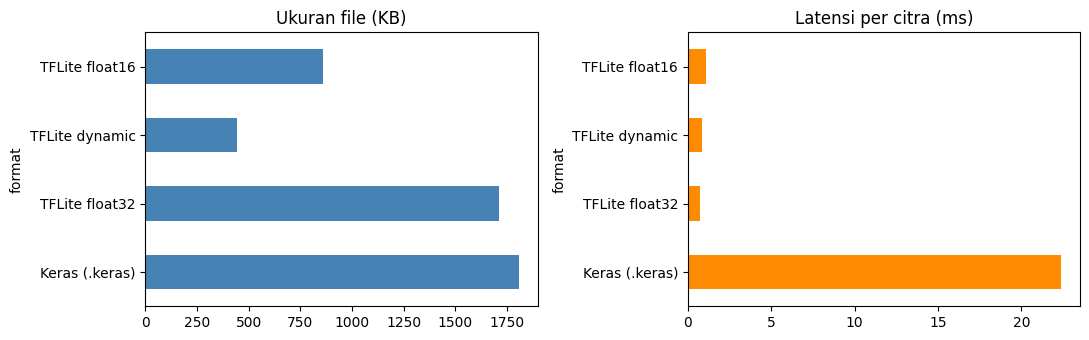

In [33]:
def convert_tflite(model, mode):
    def _convert(conv):
        if mode == "dynamic":
            conv.optimizations = [tf.lite.Optimize.DEFAULT]
        elif mode == "float16":
            conv.optimizations = [tf.lite.Optimize.DEFAULT]
            conv.target_spec.supported_types = [tf.float16]
        return conv.convert()
    try:
        return _convert(tf.lite.TFLiteConverter.from_keras_model(model))
    except Exception as e:
        print(f"from_keras_model gagal ({type(e).__name__}), mencoba jalur SavedModel...")
        model.export("outputs/saved_model")
        return _convert(tf.lite.TFLiteConverter.from_saved_model("outputs/saved_model"))


def tflite_predict_all(tflite_bytes, X):
    interp = tf.lite.Interpreter(model_content=tflite_bytes)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    preds = np.zeros(len(X), dtype=int)
    for i in range(len(X)):
        interp.set_tensor(inp["index"], X[i:i + 1])
        interp.invoke()
        preds[i] = interp.get_tensor(out["index"])[0].argmax()
    return preds


def latency_ms(fn, n=200):
    fn(0)   # pemanasan
    t0 = time.perf_counter()
    for i in range(n):
        fn(i)
    return (time.perf_counter() - t0) / n * 1000


TFLITE_BYTES, tflite_results = {}, {}
keras.models.save_model(deploy_model, "outputs/_tmp_keras_size.keras")
tflite_results["Keras (.keras)"] = {
    "ukuran_KB": round(os.path.getsize("outputs/_tmp_keras_size.keras") / 1024, 1),
    "test_acc": round(float(accuracy_score(y_test, deploy_model.predict(test_ds, verbose=0).argmax(1))), 4),
    "latensi_ms_per_citra": round(latency_ms(lambda i: deploy_model(X_test[i:i + 1], training=False)), 3),
}
os.remove("outputs/_tmp_keras_size.keras")

for mode in ["float32", "dynamic", "float16"]:
    data = convert_tflite(deploy_model, mode)
    TFLITE_BYTES[mode] = data
    interp = tf.lite.Interpreter(model_content=data); interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    def run_one(i, interp=interp, inp=inp, out=out):
        interp.set_tensor(inp["index"], X_test[i:i + 1]); interp.invoke(); return interp.get_tensor(out["index"])
    tflite_results[f"TFLite {mode}"] = {
        "ukuran_KB": round(len(data) / 1024, 1),
        "test_acc": round(float(accuracy_score(y_test, tflite_predict_all(data, X_test))), 4),
        "latensi_ms_per_citra": round(latency_ms(run_one), 3),
    }

tflite_df = pd.DataFrame(tflite_results).T
tflite_df.index.name = "format"
tflite_df.to_csv("outputs/perbandingan_tflite.csv")
display(tflite_df)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
tflite_df["ukuran_KB"].plot(kind="barh", ax=ax[0], color="steelblue"); ax[0].set_title("Ukuran file (KB)")
tflite_df["latensi_ms_per_citra"].plot(kind="barh", ax=ax[1], color="darkorange"); ax[1].set_title("Latensi per citra (ms)")
plt.tight_layout(); plt.savefig("figures/14_tflite_perbandingan.png", dpi=150); plt.show()

In [34]:
# Pilih varian TFLite untuk deployment: terkecil dengan penurunan akurasi <= 0,002
base_acc = tflite_results["TFLite float32"]["test_acc"]
cands = [m for m in ["float32", "dynamic", "float16"] if tflite_results[f"TFLite {m}"]["test_acc"] >= base_acc - 0.002]
chosen_tflite = min(cands, key=lambda m: tflite_results[f"TFLite {m}"]["ukuran_KB"])
with open("outputs/models/model_final.tflite", "wb") as f:
    f.write(TFLITE_BYTES[chosen_tflite])
red = 1 - tflite_results[f"TFLite {chosen_tflite}"]["ukuran_KB"] / tflite_results["Keras (.keras)"]["ukuran_KB"]
print(f"Varian TFLite dipilih: {chosen_tflite} | pengurangan ukuran vs Keras: {red:.1%}")

Varian TFLite dipilih: dynamic | pengurangan ukuran vs Keras: 75.5%


## 14. Menyimpan artefak untuk deployment

Folder `outputs/models/` berisi **tiga file** yang diunggah ke folder `models` di Hugging Face Space / GitHub: `best_model.keras` (untuk Grad-CAM), `model_final.tflite` (untuk prediksi cepat), dan `model_info.json`. Karena normalisasi berada di dalam model, aplikasi cukup mengirim citra grayscale 28x28 berskala 0-255. Fungsi `preprocess_user_image` mengubah foto biasa ke format tersebut: perbaikan orientasi, grayscale, inversi bila latar terang (Fashion-MNIST berlatar hitam), autocontrast, **padding ke persegi** (agar rasio tidak terdistorsi), lalu resize 28x28.

In [35]:
deploy_model.save("outputs/models/best_model.keras")

INFO = {
    "model_name": FINAL_NAME,
    "seed_run_terpilih": FINAL_SEED,
    "kriteria_pemilihan": "rata-rata akurasi validasi tertinggi pada ablasi inti (varian A-D)",
    "input_shape": [28, 28, 1],
    "input_range": "0-255 (normalisasi di dalam model)",
    "class_names": CLASS_NAMES,
    "test_accuracy": float(final_row["test_acc"]),
    "test_macro_f1": float(final_row["test_macro_f1"]),
    "gradcam_layer": last_conv_name,
    "tflite_variant": chosen_tflite,
}
with open("outputs/models/model_info.json", "w") as f:
    json.dump(INFO, f, indent=2)

with open("outputs/requirements_pinned.txt", "w") as f:
    f.write("\n".join([
        f"tensorflow-cpu=={tf.__version__}",
        f"numpy=={np.__version__}",
        f"pillow=={PIL.__version__}",
        f"matplotlib=={matplotlib.__version__}",
        "gradio",
    ]) + "\n")

reloaded = keras.models.load_model("outputs/models/best_model.keras")
same = np.allclose(reloaded.predict(X_test[:200], verbose=0), deploy_model.predict(X_test[:200], verbose=0), atol=1e-5)
print("Model tersimpan dan konsisten setelah di-load:", same)
print("Isi outputs/models/:", sorted(os.listdir("outputs/models")))

Model tersimpan dan konsisten setelah di-load: True
Isi outputs/models/: ['best_model.keras', 'model_final.tflite', 'model_info.json']


In [36]:
from PIL import Image, ImageOps

def preprocess_user_image(pil_img):
    """Foto/gambar bebas -> array (1, 28, 28, 1) float32 skala 0-255, siap diprediksi."""
    img = ImageOps.exif_transpose(pil_img)       # hormati orientasi foto dari HP
    img = ImageOps.grayscale(img)
    if np.asarray(img).mean() > 127:             # latar terang -> inversi agar mirip Fashion-MNIST
        img = ImageOps.invert(img)
    img = ImageOps.autocontrast(img)
    side = max(img.size)
    img = ImageOps.pad(img, (side, side), color=0)   # jadikan persegi tanpa mengubah rasio
    img = img.resize((28, 28), Image.LANCZOS)
    return np.asarray(img, dtype="float32")[np.newaxis, ..., np.newaxis]


_interp = tf.lite.Interpreter(model_path="outputs/models/model_final.tflite")
_interp.allocate_tensors()
_in, _out = _interp.get_input_details()[0], _interp.get_output_details()[0]

def predict_image(pil_img, top_k=3):
    """Prediksi cepat memakai model TFLite (dipakai aplikasi deployment)."""
    _interp.set_tensor(_in["index"], preprocess_user_image(pil_img))
    _interp.invoke()
    p = _interp.get_tensor(_out["index"])[0]
    order = p.argsort()[::-1][:top_k]
    return [(CLASS_NAMES[i], float(p[i])) for i in order]

def explain_image(pil_img):
    """Grad-CAM untuk satu gambar: kembalikan (citra 28x28, peta panas 28x28, kelas prediksi)."""
    x = preprocess_user_image(pil_img)
    cam = gradcam_batch(x)[0]
    return x[0], cam, CLASS_NAMES[int(reloaded.predict(x, verbose=0).argmax())]

demo = Image.fromarray(X_test[0, :, :, 0].astype("uint8"))
print("Label asli     :", CLASS_NAMES[y_test[0]])
print("Prediksi TFLite:", predict_image(demo))
_, cam_demo, name_demo = explain_image(demo)
print("Grad-CAM OK, kelas prediksi:", name_demo, "| bentuk peta panas:", cam_demo.shape)

Label asli     : Ankle boot
Prediksi TFLite: [('Ankle boot', 0.999998927116394), ('Sneaker', 1.0511436130400398e-06), ('Sandal', 3.22517941242495e-08)]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Grad-CAM OK, kelas prediksi: Ankle boot | bentuk peta panas: (28, 28)


Foto terbaca: 50 (seharusnya 50)
Uji eksternal: 27/50 benar = 0.540 (95% CI Wilson: 0.404 - 0.670)
Pembanding, akurasi data uji resmi model final: 0.9375


,benar,total
kelas_asli,,
Ankle boot,2,5
Bag,4,5
Coat,3,5
Dress,4,5
Pullover,1,5
Sandal,4,5
Shirt,1,5
Sneaker,1,5
T-shirt/top,3,5


,file,kelas_asli,prediksi,keyakinan,benar
0,Kaos krem _ Krem polos.jpeg,T-shirt/top,Shirt,0.656,False
3,WhatsApp Image 2026-11-06 at 16.19.36.jpeg,T-shirt/top,Pullover,0.872,False
5,1.jpeg,Trouser,Dress,0.685,False
10,1.jpeg,Pullover,Shirt,0.512,False
11,2.jpeg,Pullover,Coat,0.988,False
12,3.jpeg,Pullover,Coat,0.538,False
13,4.jpeg,Pullover,Shirt,0.470,False
18,4.jpeg,Dress,Shirt,0.455,False
20,Allegra K Women's Winter Coat - DarkGrey.jpg,Coat,T-shirt/top,0.388,False
24,brown jacket for everyday style.jpg,Coat,Dress,0.592,False


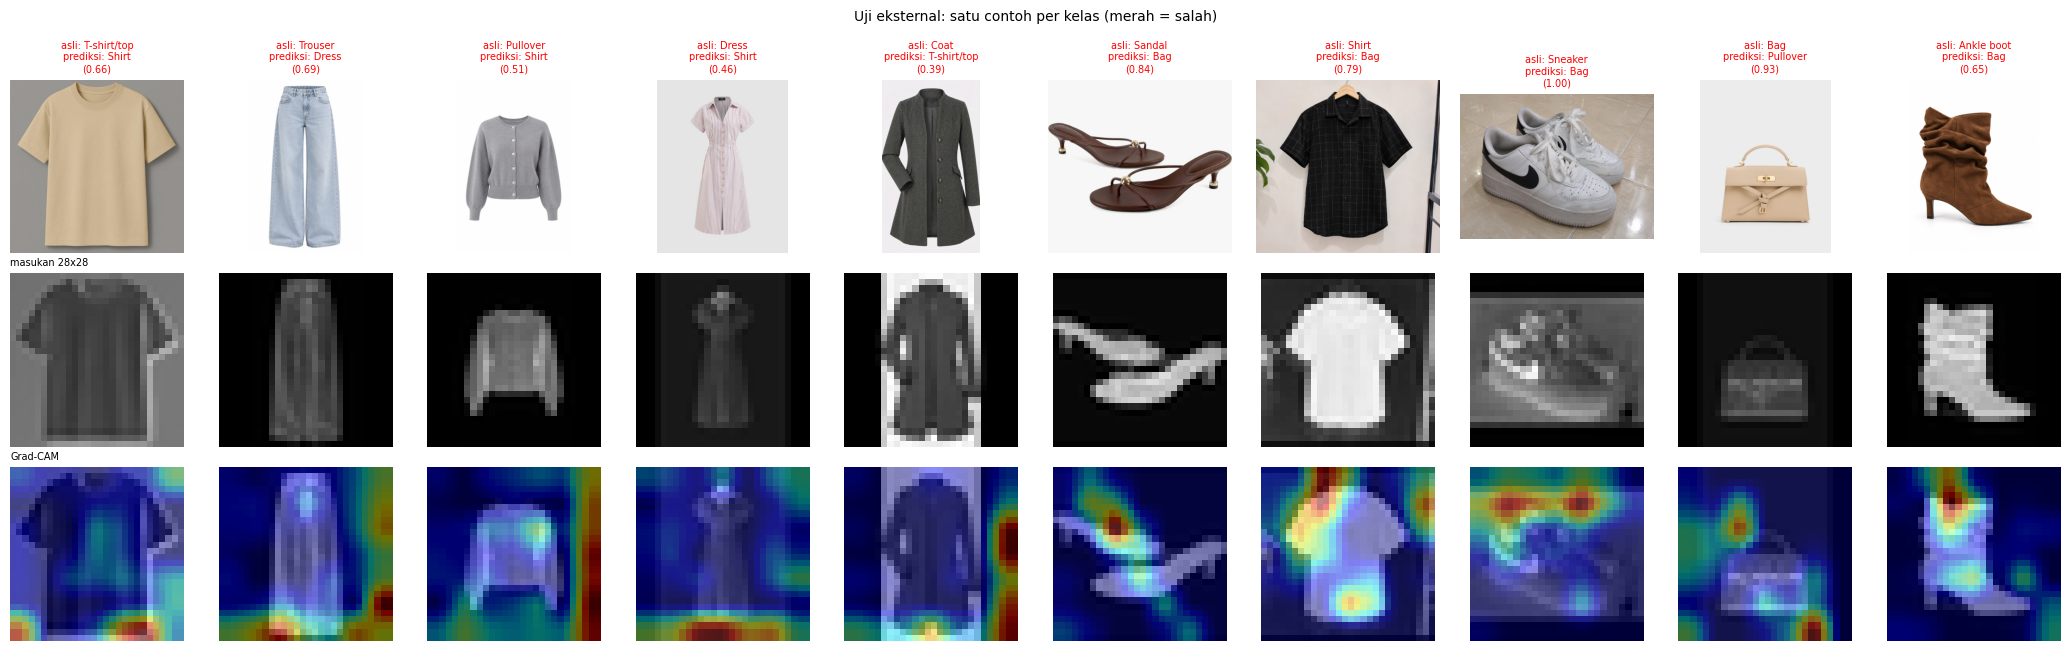

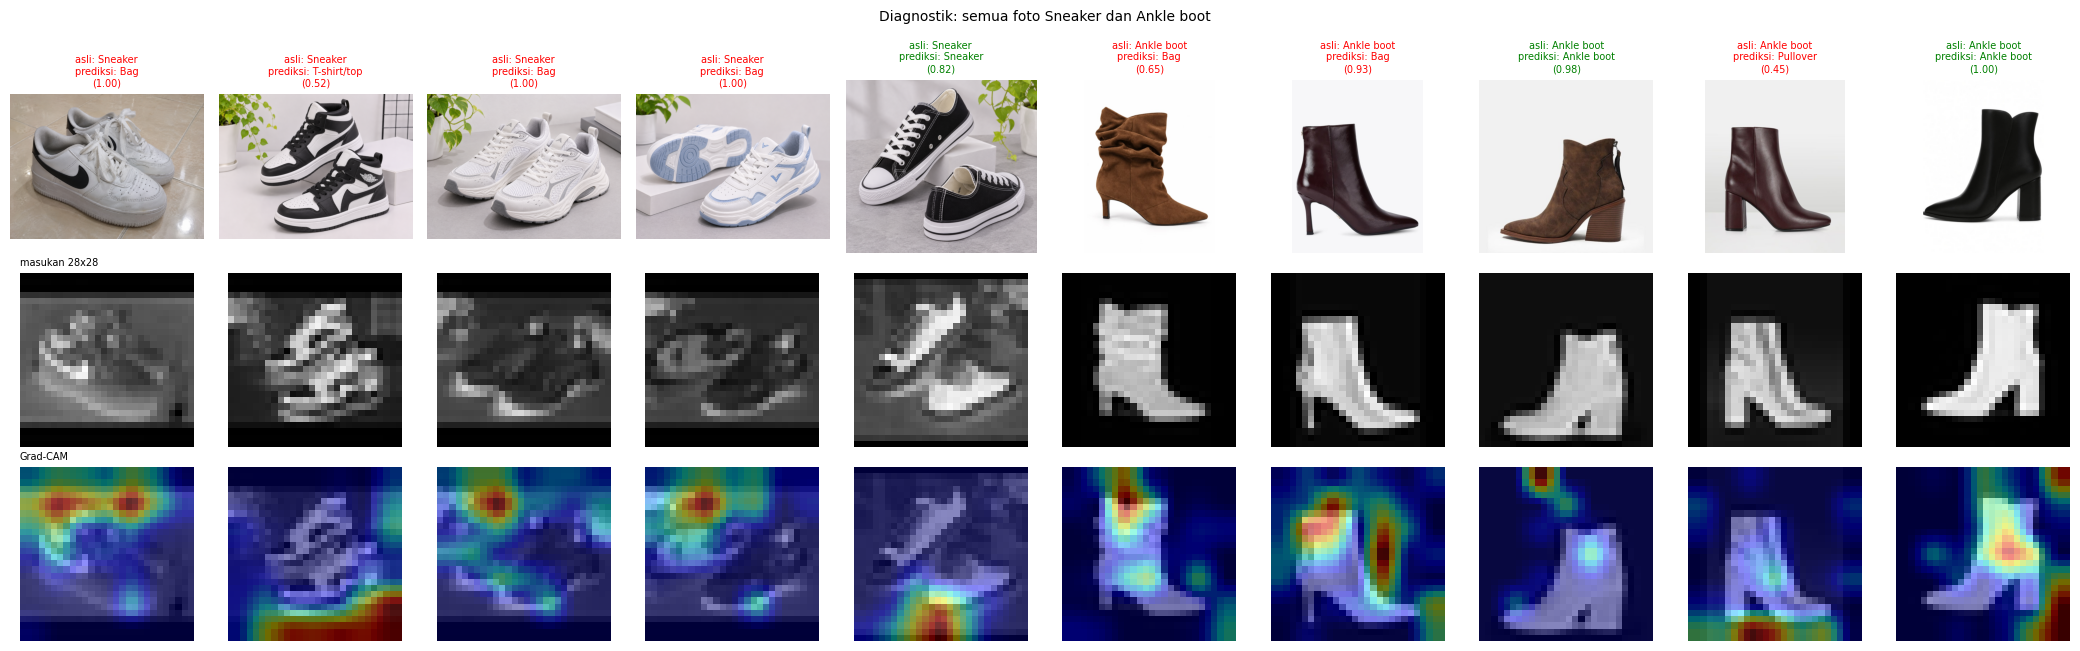

In [43]:
# ===== Uji eksternal: foto sendiri (5 per kelas) =====
# Hanya untuk pelaporan. Jangan dipakai untuk memilih model atau mengubah hyperparameter.
import glob

EXT_ROOT = "foto_uji/Uji coba2"

# nama folder (persis seperti di Colab) -> indeks kelas
FOLDER_TO_CLASS = {"T-Shirt_top": 0, "Trouser": 1, "Pullover": 2, "Dress": 3, "Coat": 4,
                   "Sandal": 5, "Shirt": 6, "Sneaker": 7, "bag": 8, "Ankle boot": 9}

def probs_tflite(pil_img):
    _interp.set_tensor(_in["index"], preprocess_user_image(pil_img))
    _interp.invoke()
    return _interp.get_tensor(_out["index"])[0].copy()

rows, imgs, true_idx, pred_idx = [], [], [], []
for folder, cls in FOLDER_TO_CLASS.items():
    for path in sorted(glob.glob(f"{EXT_ROOT}/{folder}/*")):
        try:
            img = Image.open(path); img.load()
        except Exception:
            print("dilewati (bukan gambar):", path); continue
        p = probs_tflite(img)
        pred = int(p.argmax())
        rows.append({"file": os.path.basename(path), "kelas_asli": CLASS_NAMES[cls],
                     "prediksi": CLASS_NAMES[pred], "keyakinan": round(float(p.max()), 3),
                     "benar": pred == cls})
        imgs.append(img); true_idx.append(cls); pred_idx.append(pred)

print("Foto terbaca:", len(rows), "(seharusnya 50)")
assert len(rows) > 0, "Tidak ada foto terbaca. Cek EXT_ROOT dan nama folder."
ext = pd.DataFrame(rows)
ext.to_csv("outputs/uji_eksternal_foto_sendiri.csv", index=False)

# Akurasi dan selang kepercayaan Wilson 95%
n, k = len(ext), int(ext["benar"].sum())
ph, z = k / n, 1.96
center = (ph + z * z / (2 * n)) / (1 + z * z / n)
half = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / (1 + z * z / n)
EXT_ACC = {"n_foto": n, "akurasi": ph, "ci95_wilson": [center - half, center + half]}
print(f"Uji eksternal: {k}/{n} benar = {ph:.3f} (95% CI Wilson: {center-half:.3f} - {center+half:.3f})")
print(f"Pembanding, akurasi data uji resmi model final: {final_row['test_acc']:.4f}")

display(ext.groupby("kelas_asli")["benar"].agg(["sum", "count"]).rename(columns={"sum": "benar", "count": "total"}))
display(ext[~ext["benar"]])   # daftar foto yang salah


def gallery(indices, fname, title=None):
    """Baris 1: foto asli | baris 2: masukan 28x28 yang dilihat model | baris 3: Grad-CAM kelas prediksi."""
    m = len(indices)
    fig, axes = plt.subplots(3, m, figsize=(2.1 * m, 6.6), squeeze=False)
    for c, i in enumerate(indices):
        x28 = preprocess_user_image(imgs[i])
        cam = gradcam_batch(x28, class_idx=[pred_idx[i]])[0]
        axes[0, c].imshow(imgs[i]); axes[0, c].axis("off")
        axes[0, c].set_title(f"asli: {CLASS_NAMES[true_idx[i]]}\nprediksi: {CLASS_NAMES[pred_idx[i]]}\n({rows[i]['keyakinan']:.2f})",
                             fontsize=7, color="green" if rows[i]["benar"] else "red")
        axes[1, c].imshow(x28[0, :, :, 0], cmap="gray", vmin=0, vmax=255); axes[1, c].axis("off")
        overlay(axes[2, c], x28[0], cam)
    axes[1, 0].set_title("masukan 28x28", fontsize=7, loc="left")
    axes[2, 0].set_title("Grad-CAM", fontsize=7, loc="left")
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()


# Galeri 1: satu contoh per kelas (diprioritaskan yang salah)
show = []
for cls in range(10):
    idx = [i for i in range(n) if true_idx[i] == cls]
    wrong = [i for i in idx if not rows[i]["benar"]]
    show.append((wrong or idx)[0])
gallery(show, "figures/15_uji_eksternal.png", "Uji eksternal: satu contoh per kelas (merah = salah)")

# Galeri 2 (diagnostik): semua foto Sneaker dan Ankle boot
shoes = [i for i in range(n) if true_idx[i] in (7, 9)]
gallery(shoes, "figures/15b_uji_eksternal_sepatu.png", "Diagnostik: semua foto Sneaker dan Ankle boot")

with open("outputs/uji_eksternal_ringkasan.json", "w") as f:
    json.dump(EXT_ACC, f, indent=2, default=float)

## 15. Ringkasan angka untuk laporan, README, dan video

Sel ini mengumpulkan semua angka kunci dari run ini ke satu berkas (`outputs/ringkasan_angka_laporan.json`). **Salin angka laporan, README, dan video dari sini** agar konsisten. Ketentuan tugas mewajibkan dataset, arsitektur, dan hasil evaluasi sama di laporan, kode, dan video.

In [44]:
fa = agg.loc[FINAL_NAME]
SUMMARY = {
    "model_final": FINAL_NAME,
    "seed_run_terpilih": FINAL_SEED,
    "ukuran_data": DATA_COUNTS,
    "parameter_model_final": int(deploy_model.count_params()),
    "val_acc_run_terpilih": float(final_row["val_acc"]),
    "test_acc_run_terpilih": float(final_row["test_acc"]),
    "test_macro_f1_run_terpilih": float(final_row["test_macro_f1"]),
    "test_acc_ci95_bootstrap": list(ACC_CI),
    "antar_seed_model_final": {"n_run": int(fa["n_run"]),
                               "test_acc_mean": float(fa["test_acc_mean"]), "test_acc_std": float(fa["test_acc_std"])},
    "mlp_baseline": {"test_acc_mean": float(agg.loc["MLP_baseline", "test_acc_mean"]),
                     "test_acc_std": float(agg.loc["MLP_baseline", "test_acc_std"])},
    "mobilenetv2_tl_test_acc": float(agg.loc["MobileNetV2_TL", "test_acc_mean"]),
    "mcnemar_final_vs_mlp": MCNEMAR,
    "tflite_dipilih": {"varian": chosen_tflite, **tflite_results[f"TFLite {chosen_tflite}"]},
    "ukuran_keras_KB": tflite_results["Keras (.keras)"]["ukuran_KB"],
    "gradcam_masking": gradcam_eval.set_index("skenario")["akurasi"].to_dict(),
    "kelas_tersulit": per_class.index[0],
    "kesalahan_terbanyak": pairs_df.head(3).to_dict("records"),
}
with open("outputs/ringkasan_angka_laporan.json", "w") as f:
    json.dump(SUMMARY, f, indent=2, default=lambda o: float(o))
print(json.dumps(SUMMARY, indent=2, default=lambda o: float(o)))

{
  "model_final": "CNN_C_BN_Dropout",
  "seed_run_terpilih": 44,
  "ukuran_data": {
    "latih_awal_keras": 60000,
    "dibuang_saat_pembersihan": 0,
    "latih_setelah_pembersihan": 60000,
    "latih": 54000,
    "validasi": 6000,
    "uji": 10000
  },
  "parameter_model_final": 436650,
  "val_acc_run_terpilih": 0.947,
  "test_acc_run_terpilih": 0.9375,
  "test_macro_f1_run_terpilih": 0.9372,
  "test_acc_ci95_bootstrap": [
    0.9325,
    0.942
  ],
  "antar_seed_model_final": {
    "n_run": 3,
    "test_acc_mean": 0.937,
    "test_acc_std": 0.0024
  },
  "mlp_baseline": {
    "test_acc_mean": 0.893,
    "test_acc_std": 0.0045
  },
  "mobilenetv2_tl_test_acc": 0.9046,
  "mcnemar_final_vs_mlp": {
    "mlp_salah_final_benar": 656,
    "mlp_benar_final_salah": 172,
    "p_value": 2.7695874320218057e-67
  },
  "tflite_dipilih": {
    "varian": "dynamic",
    "ukuran_KB": 442.0,
    "test_acc": 0.937,
    "latensi_ms_per_citra": 0.873
  },
  "ukuran_keras_KB": 1806.3,
  "gradcam_masking":

In [45]:
# Kemas hasil agar mudah diunduh dari Colab
shutil.make_archive("outputs/models_untuk_upload", "zip", "outputs/models")
shutil.make_archive("figures_laporan", "zip", "figures")
print("Dibuat: outputs/models_untuk_upload.zip dan figures_laporan.zip")
try:
    from google.colab import files
    files.download("outputs/models_untuk_upload.zip")
    files.download("figures_laporan.zip")
    files.download("outputs/ringkasan_angka_laporan.json")
except ImportError:
    pass

Dibuat: outputs/models_untuk_upload.zip dan figures_laporan.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 16. Pemetaan keluaran notebook ke format laporan

| Poin laporan | Sumber di notebook / file |
|---|---|
| Pengembangan model | Baseline MLP -> CNN -> ablasi (BN, Dropout, augmentasi) -> optimizer, kedalaman, learning rate -> transfer learning: `perbandingan_model.csv`, `hasil_per_run.csv` |
| Dataset dan EDA | Bagian 2, gambar `01`-`03` |
| Preprocessing dan input pipeline | Bagian 3 (termasuk 3.5 `tf.data`), `ringkasan_pembersihan_data.csv`, `ukuran_data.json`, gambar `04` dan `04b` |
| Model dan justifikasi | Bagian 4-9b, `tabel_arsitektur.csv`, gambar `05`, `06`, `10_arsitektur_cnn.png` |
| Dua fitur unik | Bagian 12 (Grad-CAM: gambar `11`-`13`, `gradcam_uji_masking.csv`) dan Bagian 13 (TFLite: gambar `14`, `perbandingan_tflite.csv`) |
| Evaluasi dan analisis | Bagian 10, gambar `07`-`09b`, `classification_report.csv`, `pasangan_kelas_tertukar.csv` |
| Teknologi | `environment.json` |
| Deployment | `outputs/models/` (tiga file), `app.py`, `requirements.txt`, `README.md` |
| Angka konsisten | `ringkasan_angka_laporan.json` |

In [42]:
   import zipfile, os
   zipfile.ZipFile("foto_uji.zip").extractall("foto_uji")
   print(os.listdir("foto_uji"))

['Uji coba2']
